# Proyecto Estadísticas de YouTube - Avance II

## Análisis estadístico y modelo NLP para predicción de desempeño

En este notebook se desarrolla el segundo avance del proyecto **Estadísticas de YouTube**.

El objetivo es construir un modelo de Procesamiento de Lenguaje Natural (NLP) capaz de clasificar el desempeño de un video de YouTube utilizando principalmente la información contenida en sus comentarios.

El desempeño se representa a partir del número de visualizaciones (`Views`) y se divide en dos categorías:

- Desempeño bajo.
- Desempeño alto.

Para desarrollar el proyecto se realizan las siguientes etapas:

- Carga y exploración de los datos.
- Limpieza y evaluación de calidad.
- Análisis estadístico descriptivo.
- Estudio de distribuciones y valores atípicos.
- Correlaciones de Pearson y Spearman.
- Análisis de sentimientos.
- Preprocesamiento de comentarios.
- Representación textual mediante TF-IDF.
- Creación y selección de características.
- Comparación de múltiples modelos de clasificación.
- Validación cruzada.
- Optimización de hiperparámetros.
- Evaluación mediante Accuracy, Precision, Recall, F1-score y ROC-AUC.
- Interpretación de las características más importantes.
- Almacenamiento del modelo para su posterior despliegue.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

# Rutas correctas en Google Drive (encontradas en MyDrive directamente)
ruta_videos_drive = "/content/drive/MyDrive/videos-stats.csv"
ruta_comments_drive = "/content/drive/MyDrive/comments.csv"

# Rutas locales alternativas
ruta_videos_local = "/content/videos-stats.csv"
ruta_comments_local = "/content/comments.csv"

# Selección de la ruta correcta para videos
if os.path.exists(ruta_videos_drive):
    ruta_videos = ruta_videos_drive
elif os.path.exists(ruta_videos_local):
    ruta_videos = ruta_videos_local
else:
    ruta_videos = ruta_videos_drive

# Selección de la ruta correcta para comentarios
if os.path.exists(ruta_comments_drive):
    ruta_comments = ruta_comments_drive
elif os.path.exists(ruta_comments_local):
    ruta_comments = ruta_comments_local
else:
    ruta_comments = ruta_comments_drive

# Carga de datasets
videos = pd.read_csv(ruta_videos)
comments = pd.read_csv(ruta_comments)

print(f"Dataset de videos cargado correctamente desde: {ruta_videos}")
print(f"Dataset de comentarios cargado correctamente desde: {ruta_comments}")

Dataset de videos cargado correctamente desde: /content/drive/MyDrive/videos-stats.csv
Dataset de comentarios cargado correctamente desde: /content/drive/MyDrive/comments.csv


## 1. Exploración inicial de los datos

Primero se revisará el tamaño de los datasets, sus columnas, tipos de variables y algunos registros para comprender la estructura de la información disponible.

In [ ]:
print("Dimensiones del dataset de videos:")
print(videos.shape)

print("\nDimensiones del dataset de comentarios:")
print(comments.shape)

Dimensiones del dataset de videos:
(1881, 8)

Dimensiones del dataset de comentarios:
(18409, 5)


In [ ]:
print("PRIMEROS REGISTROS DE VIDEOS:")
display(videos.head())

print("\nPRIMEROS REGISTROS DE COMENTARIOS:")
display(comments.head())

PRIMEROS REGISTROS DE VIDEOS:


,Unnamed: 0,Title,Video ID,Published At,Keyword,Likes,Comments,Views
0,0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0
3,3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,kXiYSI7H2b0,2022-08-23,tech,71566.0,1426.0,922918.0
4,4,Best Back to School Tech 2022!,ErMwWXQxHp0,2022-08-08,tech,96513.0,5155.0,1855644.0



PRIMEROS REGISTROS DE COMENTARIOS:


,Unnamed: 0,Video ID,Comment,Likes,Sentiment
0,0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0
3,3,wAZZ-UWGVHI,Whenever I go to a place that doesn’t take App...,8.0,0.0
4,4,wAZZ-UWGVHI,"Apple Pay is so convenient, secure, and easy t...",34.0,2.0


In [ ]:
print("COLUMNAS DEL DATASET DE VIDEOS:")
print(videos.columns.tolist())

print("\nCOLUMNAS DEL DATASET DE COMENTARIOS:")
print(comments.columns.tolist())

COLUMNAS DEL DATASET DE VIDEOS:
['Unnamed: 0', 'Title', 'Video ID', 'Published At', 'Keyword', 'Likes', 'Comments', 'Views']

COLUMNAS DEL DATASET DE COMENTARIOS:
['Unnamed: 0', 'Video ID', 'Comment', 'Likes', 'Sentiment']


In [ ]:
# Eliminar columna de índice innecesaria

if "Unnamed: 0" in videos.columns:
    videos = videos.drop(columns=["Unnamed: 0"])

if "Unnamed: 0" in comments.columns:
    comments = comments.drop(columns=["Unnamed: 0"])

print("Columnas de videos:")
print(videos.columns.tolist())

print("\nColumnas de comentarios:")
print(comments.columns.tolist())

Columnas de videos:
['Title', 'Video ID', 'Published At', 'Keyword', 'Likes', 'Comments', 'Views']

Columnas de comentarios:
['Video ID', 'Comment', 'Likes', 'Sentiment']


In [ ]:
print("INFORMACIÓN DEL DATASET DE VIDEOS:")
videos.info()

print("\n" + "="*60)

print("\nINFORMACIÓN DEL DATASET DE COMENTARIOS:")
comments.info()

INFORMACIÓN DEL DATASET DE VIDEOS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1881 entries, 0 to 1880
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1881 non-null   object 
 1   Video ID      1881 non-null   object 
 2   Published At  1881 non-null   object 
 3   Keyword       1881 non-null   object 
 4   Likes         1879 non-null   float64
 5   Comments      1879 non-null   float64
 6   Views         1879 non-null   float64
dtypes: float64(3), object(4)
memory usage: 103.0+ KB


INFORMACIÓN DEL DATASET DE COMENTARIOS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18409 entries, 0 to 18408
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Video ID   18409 non-null  object 
 1   Comment    18408 non-null  object 
 2   Likes      18409 non-null  float64
 3   Sentiment  18409 non-null  float64
dtypes: float64(2), object(2

In [ ]:
print("VALORES NULOS EN VIDEOS:")
display(videos.isnull().sum().to_frame("Valores nulos"))

print("\nVALORES NULOS EN COMENTARIOS:")
display(comments.isnull().sum().to_frame("Valores nulos"))

VALORES NULOS EN VIDEOS:


,Valores nulos
Title,0
Video ID,0
Published At,0
Keyword,0
Likes,2
Comments,2
Views,2



VALORES NULOS EN COMENTARIOS:


,Valores nulos
Video ID,0
Comment,1
Likes,0
Sentiment,0


In [ ]:
print("Filas completamente duplicadas en videos:")
print(videos.duplicated().sum())

print("\nVideo ID repetidos:")
print(videos["Video ID"].duplicated().sum())

print("\nComentarios duplicados antes de la limpieza:")
print(comments.duplicated().sum())

print("\nComentarios sin texto:")
print(comments["Comment"].isnull().sum())

# Eliminar filas completamente duplicadas
comments = (
    comments
    .drop_duplicates()
    .reset_index(drop=True)
)

# Eliminar comentarios sin texto
comments = (
    comments
    .dropna(subset=["Comment"])
    .reset_index(drop=True)
)

print("\nCantidad de comentarios después de la limpieza:")
print(len(comments))

print("\nDuplicados restantes:")
print(comments.duplicated().sum())

print("\nComentarios nulos restantes:")
print(comments["Comment"].isnull().sum())

Filas completamente duplicadas en videos:
0

Video ID repetidos:
12

Comentarios duplicados antes de la limpieza:
148

Comentarios sin texto:
1

Cantidad de comentarios después de la limpieza:
18260

Duplicados restantes:
0

Comentarios nulos restantes:
0


In [ ]:
videos_repetidos = videos[
    videos["Video ID"].duplicated(keep=False)
].sort_values("Video ID")

display(videos_repetidos)

,Title,Video ID,Published At,Keyword,Likes,Comments,Views
1714,Vikram Vedha Movie Teaser Review | KRK | #krkr...,2FYvHn12pOQ,2022-08-24,movies,-1.0,105.0,1541874.0
1055,Vikram Vedha Movie Teaser Review | KRK | #krkr...,2FYvHn12pOQ,2022-08-24,reaction,29728.0,8832.0,405791.0
2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0
88,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,gaming,63825.0,3338.0,1564007.0
1501,Computer Scientist Explains Machine Learning i...,5q87K1WaoFI,2021-08-18,computer science,42940.0,1735.0,1407319.0
1832,Computer Scientist Explains Machine Learning i...,5q87K1WaoFI,2021-08-18,machine learning,15137.0,181.0,906372.0
1762,Python Machine Learning Tutorial (Data Science),7eh4d6sabA0,2020-09-17,data science,7555.0,442.0,295344.0
1835,Python Machine Learning Tutorial (Data Science),7eh4d6sabA0,2020-09-17,machine learning,1237.0,16.0,32605.0
1554,🚨 DÉPÊCHEZ-VOUS 🚨 Ces PROMOS disparaissent bie...,96mrgd8-3yE,2022-08-24,nintendo,406.0,57.0,13184.0
1595,🚨 DÉPÊCHEZ-VOUS 🚨 Ces PROMOS disparaissent bie...,96mrgd8-3yE,2022-08-24,xbox,406.0,57.0,13184.0


### Estadística descriptiva inicial

Se calcularán estadísticas básicas de las variables numéricas para conocer su comportamiento general, incluyendo media, desviación estándar, mínimo, máximo y cuartiles.

In [ ]:
estadisticas = videos[
    ["Likes", "Comments", "Views"]
].describe()

estadisticas

,Likes,Comments,Views
count,1.879000e+03,1879.000000,1.879000e+03
mean,1.700610e+05,7863.331559,1.161292e+07
std,7.962293e+05,37879.964926,1.084450e+08
min,-1.000000e+00,-1.000000,2.500000e+01
25%,2.672500e+03,199.000000,8.451500e+04
50%,1.478700e+04,814.000000,5.917210e+05
75%,6.090600e+04,3377.500000,2.804978e+06
max,1.644556e+07,732818.000000,4.034122e+09


In [ ]:
for columna in ["Likes", "Comments", "Views"]:
    cantidad_negativos = (videos[columna] < 0).sum()

    print(
        f"{columna}: {cantidad_negativos} valores negativos"
    )

Likes: 7 valores negativos
Comments: 2 valores negativos
Views: 0 valores negativos


In [ ]:
for columna in ["Likes", "Comments", "Views"]:
    videos.loc[
        videos[columna] < 0,
        columna
    ] = np.nan

print("Valores negativos convertidos a NaN.")

Valores negativos convertidos a NaN.


In [ ]:
videos[["Likes", "Comments", "Views"]].isnull().sum()

,0
Likes,9
Comments,4
Views,2


In [ ]:
videos["Published At"] = pd.to_datetime(
    videos["Published At"],
    errors="coerce"
)

print(videos["Published At"].dtype)

datetime64[ns]


In [ ]:
videos["Year"] = videos["Published At"].dt.year
videos["Month"] = videos["Published At"].dt.month
videos["DayOfWeek"] = videos["Published At"].dt.day_name()

display(
    videos[
        ["Published At", "Year", "Month", "DayOfWeek"]
    ].head()
)

,Published At,Year,Month,DayOfWeek
0,2022-08-23,2022,8,Tuesday
1,2022-08-24,2022,8,Wednesday
2,2022-08-23,2022,8,Tuesday
3,2022-08-23,2022,8,Tuesday
4,2022-08-08,2022,8,Monday


In [ ]:
videos["Title_Length"] = videos["Title"].astype(str).str.len()

videos["Title_Words"] = (
    videos["Title"]
    .astype(str)
    .str.split()
    .str.len()
)

display(
    videos[
        ["Title", "Title_Length", "Title_Words"]
    ].head()
)

,Title,Title_Length,Title_Words
0,Apple Pay Is Killing the Physical Wallet After...,98,18
1,The most EXPENSIVE thing I own.,31,6
2,My New House Gaming Setup is SICK!,34,7
3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,89,16
4,Best Back to School Tech 2022!,30,6


## 2. Análisis estadístico exploratorio

En esta sección se analizará la distribución de las principales variables numéricas del dataset, con especial atención a Likes, Comments y Views.

Este análisis permite identificar asimetrías, valores extremos y relaciones entre las variables antes de construir los modelos predictivos.

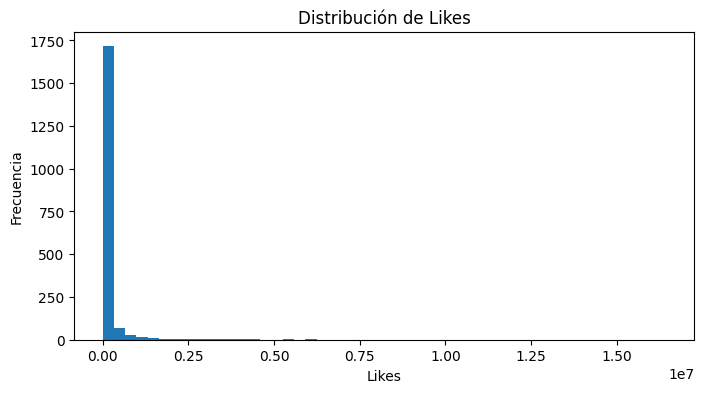

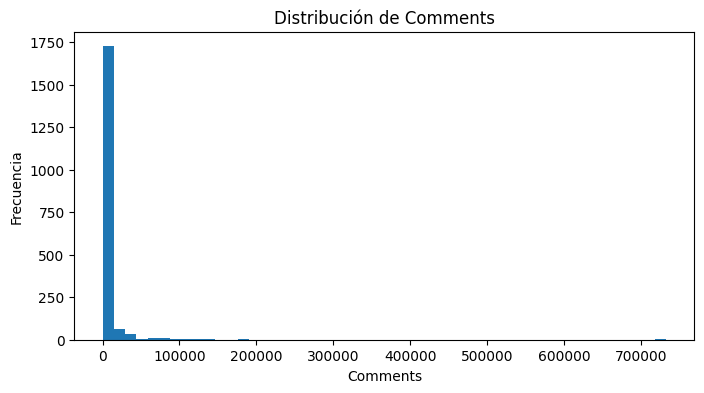

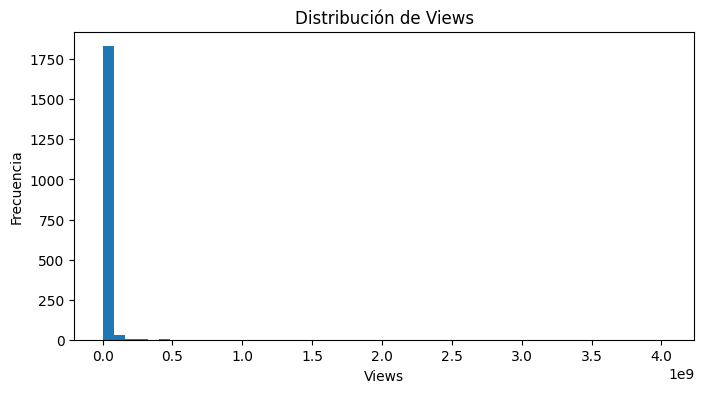

In [ ]:
variables = ["Likes", "Comments", "Views"]

for variable in variables:
    plt.figure(figsize=(8, 4))

    plt.hist(
        videos[variable].dropna(),
        bins=50
    )

    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")

    plt.show()

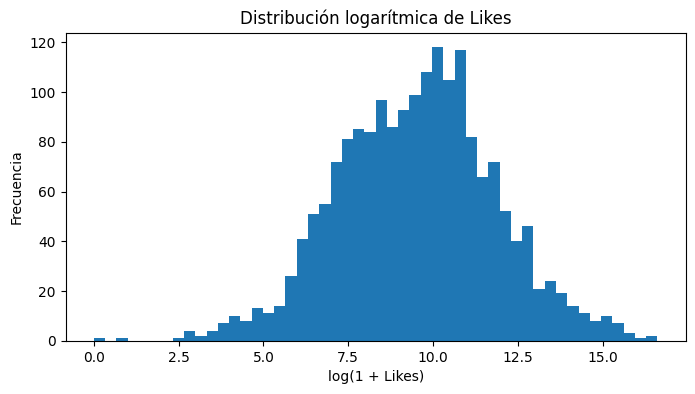

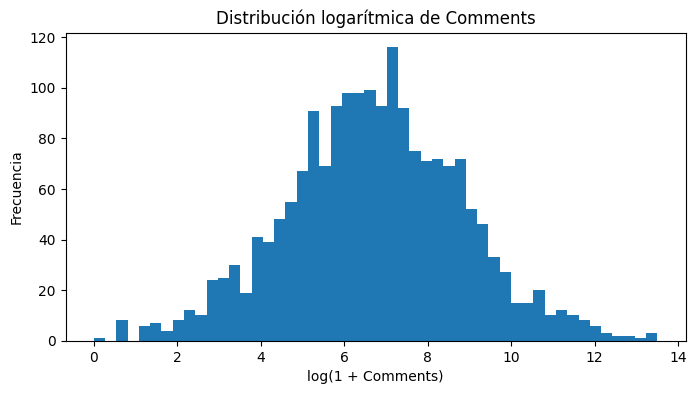

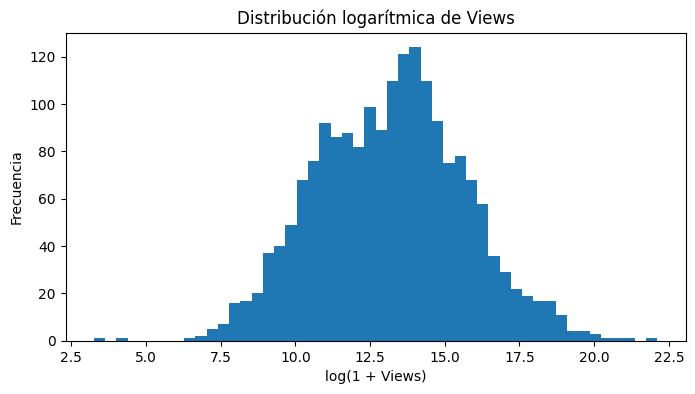

In [ ]:
for variable in variables:
    plt.figure(figsize=(8, 4))

    plt.hist(
        np.log1p(videos[variable].dropna()),
        bins=50
    )

    plt.title(f"Distribución logarítmica de {variable}")
    plt.xlabel(f"log(1 + {variable})")
    plt.ylabel("Frecuencia")

    plt.show()

### Análisis de las distribuciones

Las variables Likes, Comments y Views presentan una distribución fuertemente asimétrica hacia la derecha.

Esto significa que la mayoría de los videos tienen valores relativamente moderados, mientras que un grupo pequeño alcanza cantidades extremadamente altas de visualizaciones, likes o comentarios.

La transformación logarítmica permite observar mejor la distribución de los datos y reduce visualmente el efecto de los videos extremadamente virales.

Esta característica debe tenerse en cuenta al momento de entrenar los modelos predictivos.

### Detección de valores atípicos

Los valores atípicos pueden afectar considerablemente los modelos estadísticos y predictivos.

Para identificarlos se utilizarán diagramas de caja y el método del rango intercuartílico (IQR).

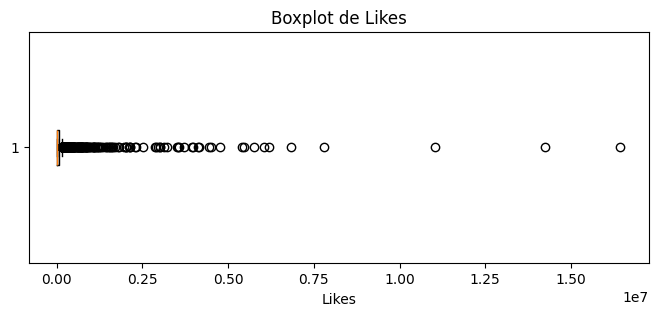

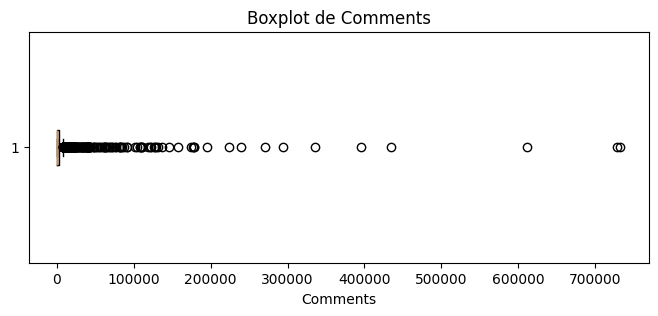

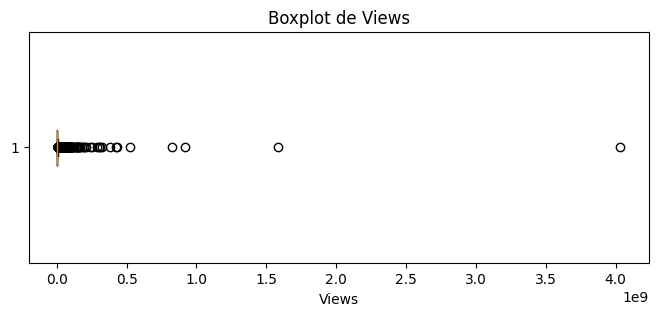

In [ ]:
for variable in variables:

    plt.figure(figsize=(8, 3))

    plt.boxplot(
        videos[variable].dropna(),
        vert=False
    )

    plt.title(f"Boxplot de {variable}")
    plt.xlabel(variable)

    plt.show()

In [ ]:
resultados_outliers = []

for variable in variables:

    Q1 = videos[variable].quantile(0.25)
    Q3 = videos[variable].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = videos[
        (videos[variable] < limite_inferior) |
        (videos[variable] > limite_superior)
    ]

    resultados_outliers.append([
        variable,
        Q1,
        Q3,
        limite_superior,
        len(outliers)
    ])

df_outliers = pd.DataFrame(
    resultados_outliers,
    columns=[
        "Variable",
        "Q1",
        "Q3",
        "Límite superior",
        "Cantidad de outliers"
    ]
)

df_outliers

,Variable,Q1,Q3,Límite superior,Cantidad de outliers
0,Likes,2695.5,61045.5,148570.50,266
1,Comments,200.0,3380.0,8150.00,246
2,Views,84515.0,2804977.5,6885671.25,288


### Análisis de valores atípicos

El método IQR permitió identificar una cantidad importante de valores atípicos en Likes, Comments y Views.

Esto es esperable en estadísticas de YouTube, ya que algunos videos pueden alcanzar niveles de popularidad muy superiores al comportamiento general del conjunto.

Estos valores no necesariamente representan errores, sino videos con comportamiento viral.

Por esta razón, no se eliminarán automáticamente. En su lugar, se considerará el uso de transformaciones logarítmicas y modelos robustos capaces de manejar relaciones no lineales.

## 3. Análisis de correlaciones

La correlación permite estudiar la relación existente entre diferentes variables numéricas.

Primero se utilizará la correlación de Pearson, que mide principalmente relaciones lineales.

In [ ]:
variables_correlacion = [
    "Likes",
    "Comments",
    "Views",
    "Title_Length",
    "Title_Words",
    "Year",
    "Month"
]

corr_pearson = videos[
    variables_correlacion
].corr(method="pearson")

corr_pearson.round(3)

,Likes,Comments,Views,Title_Length,Title_Words,Year,Month
Likes,1.000,0.892,0.754,-0.095,-0.081,-0.149,-0.052
Comments,0.892,1.000,0.660,-0.077,-0.063,-0.137,-0.030
Views,0.754,0.660,1.000,-0.024,-0.017,-0.144,-0.044
Title_Length,-0.095,-0.077,-0.024,1.000,0.919,0.164,0.100
Title_Words,-0.081,-0.063,-0.017,0.919,1.000,0.169,0.102
Year,-0.149,-0.137,-0.144,0.164,0.169,1.000,0.043
Month,-0.052,-0.030,-0.044,0.100,0.102,0.043,1.000


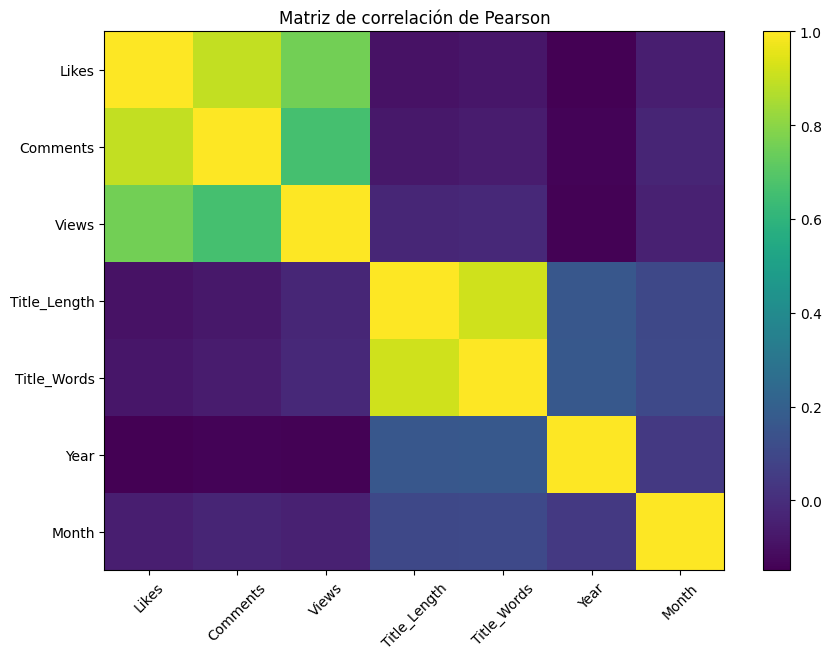

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(
    corr_pearson,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(corr_pearson.columns)),
    corr_pearson.columns,
    rotation=45
)

plt.yticks(
    range(len(corr_pearson.columns)),
    corr_pearson.columns
)

plt.title("Matriz de correlación de Pearson")

plt.show()

### Análisis de Pearson

La correlación de Pearson muestra una relación positiva importante entre las métricas de interacción.

La relación más alta aparece entre Likes y Comments, con un valor cercano a 0.89.

También existe una relación positiva entre Likes y Views, cercana a 0.75, mientras que Comments y Views presentan una correlación aproximada de 0.66.

Esto indica que los videos con mayor número de likes y comentarios tienden también a presentar una mayor cantidad de visualizaciones.

### Correlación de Spearman

Debido a que las variables presentan distribuciones muy asimétricas y numerosos valores extremos, también se calculará la correlación de Spearman.

Spearman utiliza rangos en lugar de los valores originales, por lo que puede representar mejor relaciones monotónicas cuando existen outliers.

In [ ]:
corr_spearman = videos[
    variables_correlacion
].corr(method="spearman")

corr_spearman.round(3)

,Likes,Comments,Views,Title_Length,Title_Words,Year,Month
Likes,1.000,0.873,0.949,-0.297,-0.274,-0.423,-0.183
Comments,0.873,1.000,0.839,-0.233,-0.231,-0.317,-0.132
Views,0.949,0.839,1.000,-0.271,-0.254,-0.470,-0.202
Title_Length,-0.297,-0.233,-0.271,1.000,0.927,0.186,0.105
Title_Words,-0.274,-0.231,-0.254,0.927,1.000,0.184,0.101
Year,-0.423,-0.317,-0.470,0.186,0.184,1.000,-0.041
Month,-0.183,-0.132,-0.202,0.105,0.101,-0.041,1.000


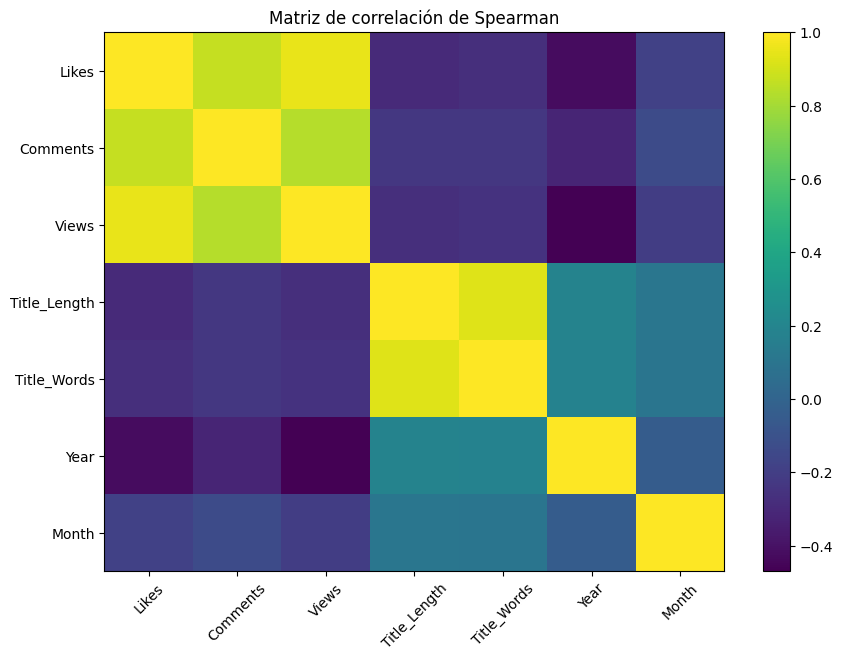

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(
    corr_spearman,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(corr_spearman.columns)),
    corr_spearman.columns,
    rotation=45
)

plt.yticks(
    range(len(corr_spearman.columns)),
    corr_spearman.columns
)

plt.title("Matriz de correlación de Spearman")

plt.show()

### Comparación entre Pearson y Spearman

Los resultados de Spearman muestran relaciones todavía más fuertes entre las principales variables de interacción.

La relación entre Likes y Views alcanza aproximadamente 0.95, indicando una relación monotónica muy alta.

Comments y Views presentan una correlación cercana a 0.84.

La diferencia entre Pearson y Spearman confirma que la presencia de valores extremos influye considerablemente en los datos.

Por esta razón, se utilizarán ambos métodos para interpretar las relaciones entre las variables.

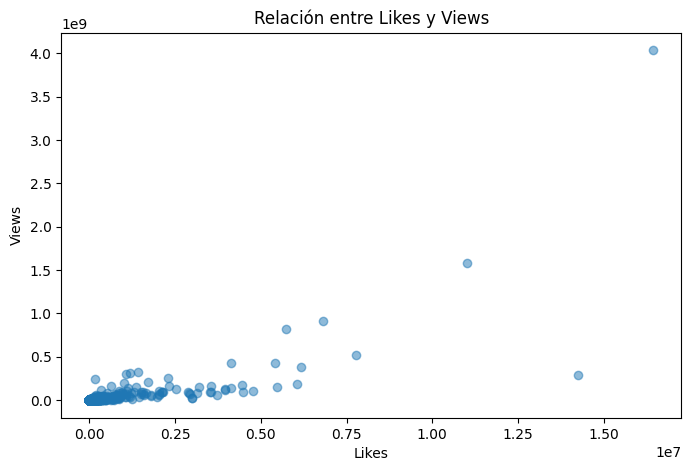

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    videos["Likes"],
    videos["Views"],
    alpha=0.5
)

plt.xlabel("Likes")
plt.ylabel("Views")
plt.title("Relación entre Likes y Views")

plt.show()

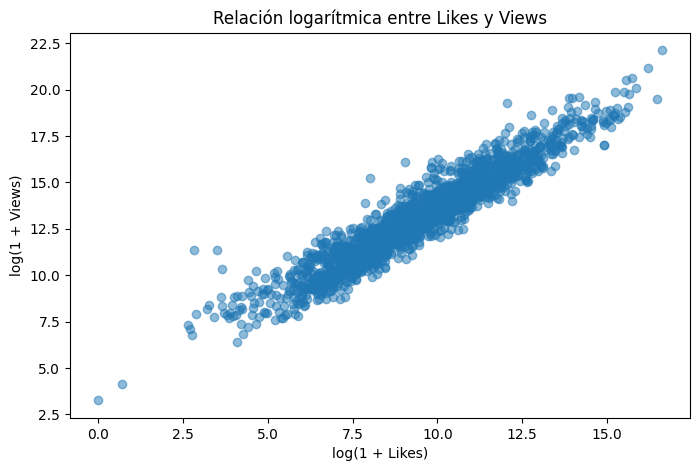

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    np.log1p(videos["Likes"]),
    np.log1p(videos["Views"]),
    alpha=0.5
)

plt.xlabel("log(1 + Likes)")
plt.ylabel("log(1 + Views)")
plt.title("Relación logarítmica entre Likes y Views")

plt.show()

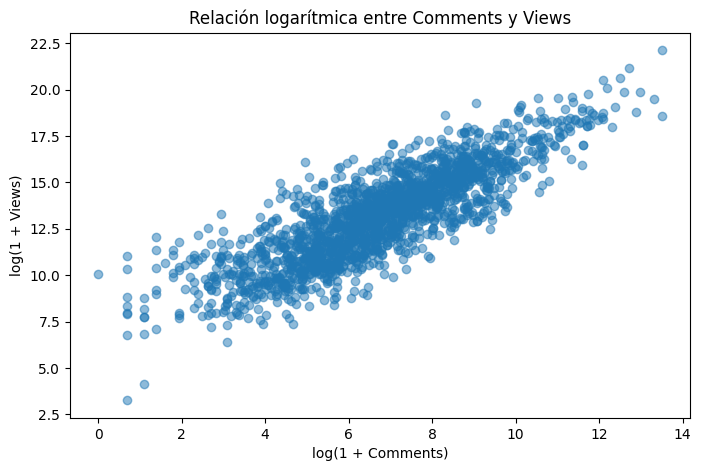

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    np.log1p(videos["Comments"]),
    np.log1p(videos["Views"]),
    alpha=0.5
)

plt.xlabel("log(1 + Comments)")
plt.ylabel("log(1 + Views)")
plt.title("Relación logarítmica entre Comments y Views")

plt.show()

### Análisis gráfico de las relaciones

Las gráficas muestran una relación positiva entre las métricas de interacción y las visualizaciones.

La representación logarítmica permite observar con mayor claridad el patrón general, ya que reduce el efecto visual producido por los videos con cantidades extremadamente altas de visualizaciones.

Likes presenta una relación especialmente fuerte con Views, lo cual coincide con los resultados obtenidos mediante las correlaciones.

In [ ]:
print("Cantidad de keywords:")
print(videos["Keyword"].nunique())

print("\nKeywords disponibles:")

print(
    videos["Keyword"]
    .value_counts()
)

Cantidad de keywords:
41

Keywords disponibles:
Keyword
crypto              50
tutorial            50
mrbeast             50
reaction            50
asmr                50
trolling            50
history             50
interview           50
cubes               50
marvel              50
machine learning    50
game development    50
data science        50
cnn                 50
physics             50
minecraft           50
sports              49
sat                 49
xbox                49
computer science    48
food                48
how-to              48
tech                48
nintendo            48
business            48
biology             47
chess               47
literature          46
music               46
mukbang             45
movies              45
google              45
bed                 44
gaming              43
apple               42
lofi                41
news                39
finance             39
animals             38
education           24
mathchemistry       15
N

In [ ]:
keyword_stats = (
    videos
    .groupby("Keyword")
    .agg(
        Videos=("Video ID", "count"),
        Views_Median=("Views", "median"),
        Views_Mean=("Views", "mean"),
        Likes_Median=("Likes", "median"),
        Comments_Median=("Comments", "median")
    )
    .sort_values(
        "Views_Median",
        ascending=False
    )
)

keyword_stats.head(10)

,Videos,Views_Median,Views_Mean,Likes_Median,Comments_Median
Keyword,,,,,
mrbeast,50,65074742.5,6.676400e+07,1687158.5,66500.0
bed,44,9359070.5,5.389323e+07,133140.0,3712.0
cubes,50,5038323.0,1.503874e+07,88548.5,1771.0
animals,38,4466776.0,9.472396e+07,27982.5,1144.0
tutorial,50,2817913.5,6.761032e+06,74692.5,2019.5
google,45,2530836.0,1.033650e+08,51622.5,3070.0
food,48,2456819.0,5.252406e+06,47811.5,2119.5
how-to,48,2023665.5,7.809285e+06,52437.5,1970.0
sports,49,1945140.0,8.601205e+06,22288.0,1116.0


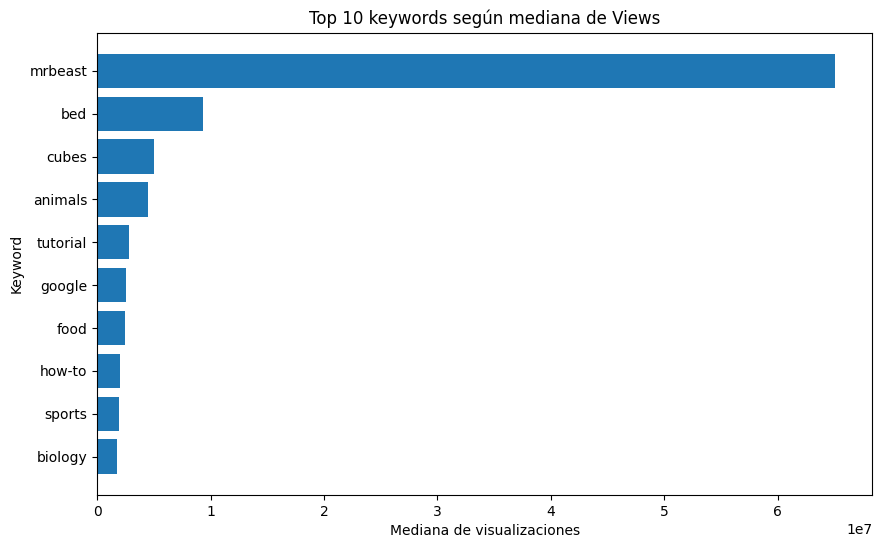

In [ ]:
top_keywords = keyword_stats.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_keywords.index[::-1],
    top_keywords["Views_Median"][::-1]
)

plt.xlabel("Mediana de visualizaciones")
plt.ylabel("Keyword")
plt.title("Top 10 keywords según mediana de Views")

plt.show()

### Análisis por Keyword

El análisis por Keyword permite comparar el comportamiento de los videos según su temática.

Se utilizó la mediana de visualizaciones como medida principal debido a la presencia de videos extremadamente virales que pueden aumentar considerablemente la media.

Esto permite realizar una comparación más representativa del comportamiento típico de los videos asociados a cada categoría.

In [ ]:
views_por_anio = (
    videos
    .groupby("Year")
    .agg(
        Cantidad_Videos=("Video ID", "count"),
        Views_Median=("Views", "median"),
        Views_Mean=("Views", "mean")
    )
)

views_por_anio

,Cantidad_Videos,Views_Median,Views_Mean
Year,,,
2007,2,52482048.0,5.248205e+07
2008,1,7178954.0,7.178954e+06
2009,9,46251795.0,1.168428e+08
2010,6,13178708.0,1.433971e+07
2011,4,34237875.5,9.794423e+07
2012,12,6826708.0,7.404389e+06
2013,6,3236613.0,2.700991e+08
2014,10,2189523.0,1.048650e+08
2015,15,3371830.0,5.657499e+06


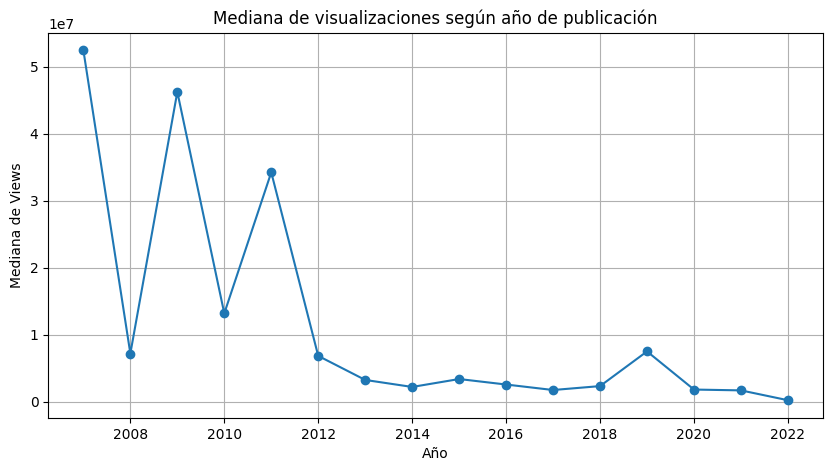

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    views_por_anio.index,
    views_por_anio["Views_Median"],
    marker="o"
)

plt.xlabel("Año")
plt.ylabel("Mediana de Views")
plt.title("Mediana de visualizaciones según año de publicación")

plt.grid()

plt.show()

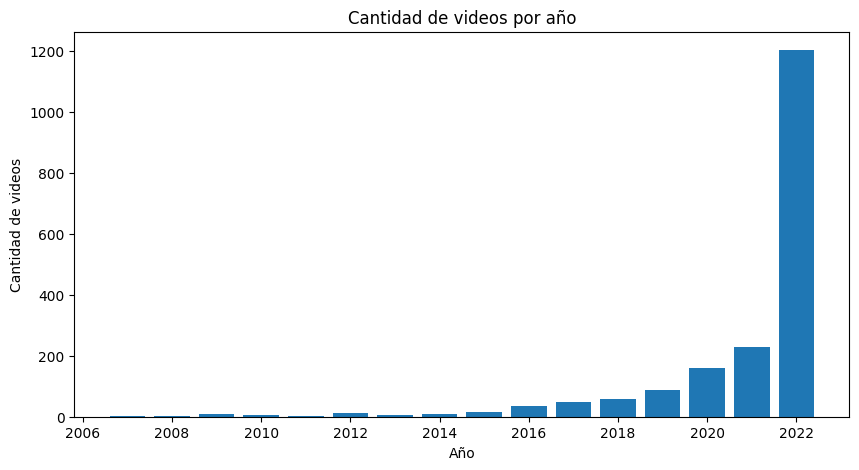

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    views_por_anio.index,
    views_por_anio["Cantidad_Videos"]
)

plt.xlabel("Año")
plt.ylabel("Cantidad de videos")
plt.title("Cantidad de videos por año")

plt.show()

### Análisis temporal

El análisis temporal permite observar cómo varían las estadísticas de los videos según el año de publicación.

Para las visualizaciones se utilizó la mediana debido a la fuerte asimetría de la variable Views.

Debe tenerse en cuenta que este dataset no representa necesariamente todos los videos publicados en YouTube durante cada año, por lo que estos resultados describen únicamente el comportamiento de la muestra analizada.

## 4. Análisis de los comentarios y sentimientos

El segundo dataset contiene comentarios asociados a los videos mediante la variable `Video ID`.

Además del texto de cada comentario, el dataset incluye una variable denominada `Sentiment`, donde:

- 0 representa sentimiento negativo.
- 1 representa sentimiento neutral.
- 2 representa sentimiento positivo.

Esta información permitirá crear nuevas características para cada video y estudiar si el comportamiento de los comentarios aporta información útil para explicar las visualizaciones.

In [ ]:
# Distribución del sentimiento

sentimiento_conteo = (
    comments["Sentiment"]
    .value_counts()
    .sort_index()
)

sentimiento_porcentaje = (
    comments["Sentiment"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

df_sentimientos = pd.DataFrame({
    "Cantidad": sentimiento_conteo,
    "Porcentaje": sentimiento_porcentaje
})

df_sentimientos.index = [
    "Negativo",
    "Neutral",
    "Positivo"
]

df_sentimientos

,Cantidad,Porcentaje
Negativo,2332,12.771084
Neutral,4610,25.246440
Positivo,11318,61.982475


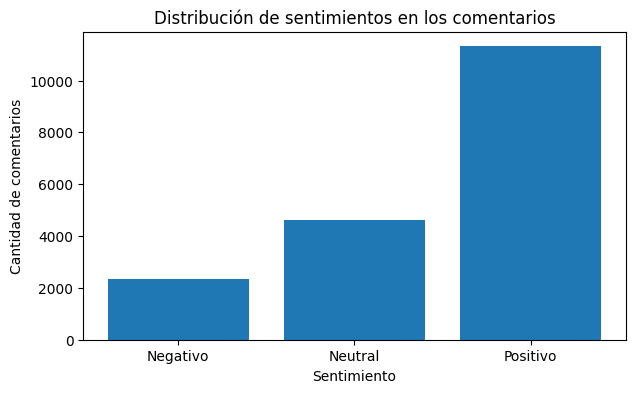

In [ ]:
plt.figure(figsize=(7, 4))

plt.bar(
    df_sentimientos.index,
    df_sentimientos["Cantidad"]
)

plt.title("Distribución de sentimientos en los comentarios")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de comentarios")

plt.show()

### Análisis del sentimiento

La mayoría de los comentarios presentes en el dataset tienen una clasificación positiva, mientras que los comentarios neutrales ocupan el segundo lugar y los negativos representan una proporción menor.

Este resultado indica que, dentro de la muestra analizada, existe una tendencia general hacia comentarios con sentimiento positivo.

Sin embargo, el sentimiento por sí solo no determina la popularidad de un video, por lo que posteriormente se estudiará su relación con otras variables.

### Creación de variables a partir de los comentarios

Para incorporar la información de los comentarios al modelo predictivo, se agruparán los registros utilizando `Video ID`.

Para cada video se calcularán las siguientes características:

- Cantidad de comentarios disponibles en el dataset.
- Promedio de likes recibidos por los comentarios.
- Sentimiento promedio.
- Proporción de comentarios positivos.
- Proporción de comentarios neutrales.
- Proporción de comentarios negativos.

In [ ]:
comentarios_por_video = (
    comments
    .groupby("Video ID")
    .agg(
        Comment_Count=("Comment", "count"),
        Comment_Likes_Mean=("Likes", "mean"),
        Sentiment_Mean=("Sentiment", "mean"),
        Positive_Ratio=("Sentiment", lambda x: (x == 2).mean()),
        Neutral_Ratio=("Sentiment", lambda x: (x == 1).mean()),
        Negative_Ratio=("Sentiment", lambda x: (x == 0).mean())
    )
    .reset_index()
)

comentarios_por_video.head()

,Video ID,Comment_Count,Comment_Likes_Mean,Sentiment_Mean,Positive_Ratio,Neutral_Ratio,Negative_Ratio
0,--ZI0dSbbNU,10,2553.9,1.9,0.9,0.1,0.0
1,--hxd1CrOqg,10,44.6,0.2,0.0,0.2,0.8
2,--ixiTypG8g,10,83.6,0.2,0.0,0.2,0.8
3,-64r1hcxtV4,10,5550.0,1.5,0.7,0.1,0.2
4,-6IgkG5yZfo,10,445.2,2.0,1.0,0.0,0.0


In [ ]:
print("Cantidad de videos con información de comentarios:")
print(comentarios_por_video["Video ID"].nunique())

print("\nDimensiones:")
print(comentarios_por_video.shape)

Cantidad de videos con información de comentarios:
1869

Dimensiones:
(1869, 7)


## 5. Integración de los datasets

Los datasets de videos y comentarios pueden relacionarse mediante la variable `Video ID`.

La integración permite combinar las estadísticas generales del video con información obtenida a partir de sus comentarios.

In [ ]:
datos_completos = videos.merge(
    comentarios_por_video,
    on="Video ID",
    how="left"
)

print("Dimensiones antes de la unión:")
print(videos.shape)

print("\nDimensiones después de la unión:")
print(datos_completos.shape)

display(datos_completos.head())

Dimensiones antes de la unión:
(1881, 12)

Dimensiones después de la unión:
(1881, 18)


,Title,Video ID,Published At,Keyword,Likes,Comments,Views,Year,Month,DayOfWeek,Title_Length,Title_Words,Comment_Count,Comment_Likes_Mean,Sentiment_Mean,Positive_Ratio,Neutral_Ratio,Negative_Ratio
0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0,2022,8,Tuesday,98,18,10,39.1,1.2,0.4,0.4,0.2
1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0,2022,8,Wednesday,31,6,10,598.2,1.8,0.9,0.0,0.1
2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0,2022,8,Tuesday,34,7,10,626.2,1.9,0.9,0.1,0.0
3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,kXiYSI7H2b0,2022-08-23,tech,71566.0,1426.0,922918.0,2022,8,Tuesday,89,16,10,528.8,1.6,0.6,0.4,0.0
4,Best Back to School Tech 2022!,ErMwWXQxHp0,2022-08-08,tech,96513.0,5155.0,1855644.0,2022,8,Monday,30,6,10,2721.7,1.6,0.6,0.4,0.0


In [ ]:
datos_completos.isnull().sum()

,0
Title,0
Video ID,0
Published At,0
Keyword,0
Likes,9
Comments,4
Views,2
Year,0
Month,0
DayOfWeek,0


### Tratamiento de videos repetidos

Se identificaron algunos `Video ID` repetidos en el dataset original.

Para el entrenamiento de los modelos se conservará un único registro por video. Esta decisión evita que el mismo video pueda aparecer simultáneamente en los conjuntos de entrenamiento y prueba, lo cual produciría fuga de información y una evaluación artificialmente optimista.

En los pocos casos donde un video aparece asociado a más de una keyword se conservará la primera categoría registrada.

In [ ]:
datos_modelo = (
    datos_completos
    .drop_duplicates(
        subset="Video ID",
        keep="first"
    )
    .copy()
)

# Eliminar únicamente registros sin variable objetivo
datos_modelo = datos_modelo.dropna(
    subset=["Views"]
)

print("Registros disponibles para modelado:")
print(datos_modelo.shape)

print("\nVideos únicos:")
print(datos_modelo["Video ID"].nunique())

Registros disponibles para modelado:
(1867, 18)

Videos únicos:
1867


## 6. Análisis preliminar de variables disponibles

Antes de construir el modelo NLP se estudió la relación entre las variables disponibles en el dataset general de videos y la variable `Views`.

Se utilizaron correlación de Spearman y Mutual Information para identificar qué características presentan mayor relación con el desempeño de los videos.

Este análisis tiene un propósito exploratorio. Aunque variables como Likes y Comments del video presentan una fuerte relación con Views, el modelo NLP final se concentrará principalmente en información obtenida de los comentarios, de acuerdo con el objetivo establecido para el proyecto.

In [ ]:
variables_numericas = [
    "Likes",
    "Comments",
    "Year",
    "Month",
    "Title_Length",
    "Title_Words",
    "Comment_Count",
    "Comment_Likes_Mean",
    "Positive_Ratio",
    "Negative_Ratio"
]

correlacion_views = (
    datos_modelo[
        variables_numericas + ["Views"]
    ]
    .corr(method="spearman")["Views"]
    .drop("Views")
    .sort_values(
        key=abs,
        ascending=False
    )
)

df_correlacion_views = correlacion_views.to_frame(
    "Correlación Spearman con Views"
)

df_correlacion_views

,Correlación Spearman con Views
Likes,0.949195
Comments,0.838519
Comment_Likes_Mean,0.714093
Year,-0.471636
Title_Length,-0.268595
Comment_Count,0.253387
Title_Words,-0.251490
Month,-0.203807
Positive_Ratio,0.144993
Negative_Ratio,-0.023216


### Mutual Information

Mutual Information permite estimar cuánto conocimiento sobre una variable contribuye a explicar otra.

A diferencia de la correlación tradicional, puede detectar relaciones no lineales.

Para reducir el efecto de la fuerte asimetría de Views, se aplicará `log1p` sobre la variable objetivo durante este análisis.

In [ ]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

X_mi = datos_modelo[
    variables_numericas
].copy()

y_mi = np.log1p(
    datos_modelo["Views"]
)

# Imputar valores faltantes
imputador_mi = SimpleImputer(
    strategy="median"
)

X_mi_imputado = imputador_mi.fit_transform(
    X_mi
)

mi = mutual_info_regression(
    X_mi_imputado,
    y_mi,
    random_state=42
)

df_mi = pd.DataFrame({
    "Variable": variables_numericas,
    "Mutual Information": mi
}).sort_values(
    "Mutual Information",
    ascending=False
)

df_mi

,Variable,Mutual Information
0,Likes,1.047860
1,Comments,0.647007
7,Comment_Likes_Mean,0.370801
2,Year,0.158586
3,Month,0.155803
8,Positive_Ratio,0.048107
6,Comment_Count,0.044759
4,Title_Length,0.044085
5,Title_Words,0.030455
9,Negative_Ratio,0.009595


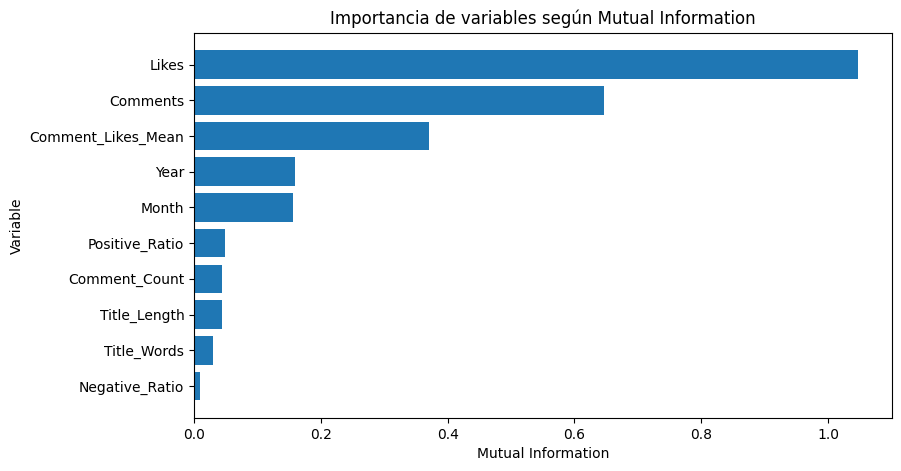

In [ ]:
plt.figure(figsize=(9, 5))

plt.barh(
    df_mi["Variable"][::-1],
    df_mi["Mutual Information"][::-1]
)

plt.xlabel("Mutual Information")
plt.ylabel("Variable")
plt.title("Importancia de variables según Mutual Information")

plt.show()

### Análisis de las variables disponibles

Los análisis de Spearman y Mutual Information muestran que Likes y Comments del video presentan una fuerte relación con Views.

Sin embargo, estas variables no serán utilizadas como predictores principales del modelo NLP final, ya que el objetivo del proyecto es estudiar cuánto puede conocerse sobre el desempeño de un video utilizando la información proveniente de sus comentarios.

Por esta razón, estos resultados se mantienen como análisis exploratorio del dataset, mientras que el modelo final utilizará el contenido textual y características estadísticas derivadas de los comentarios.

## 7. Definición del problema de NLP

El objetivo principal del proyecto es construir un modelo de Procesamiento de Lenguaje Natural capaz de predecir el desempeño de un video de YouTube utilizando la información contenida en sus comentarios.

Para representar el desempeño se utilizará la variable `Views`.

Debido a que `Views` presenta una distribución altamente asimétrica y existen videos con cantidades extremadamente altas de visualizaciones, se transformará el problema en una tarea de clasificación:

- **0 = Desempeño bajo**
- **1 = Desempeño alto**

El límite entre ambas categorías se establecerá mediante la mediana de visualizaciones.

La mediana es adecuada porque es menos sensible a los videos virales y permite obtener dos grupos aproximadamente balanceados.

El modelo final utilizará principalmente:

- Texto de los comentarios representado mediante TF-IDF.
- Cantidad de comentarios disponibles.
- Likes promedio recibidos por los comentarios.
- Proporción de comentarios positivos y negativos.
- Longitud promedio de los comentarios.

No se utilizarán `Likes` ni `Comments` del dataset general de videos como variables predictoras del modelo final, ya que se busca evaluar específicamente qué información aportan los comentarios.

In [ ]:
import re

comments_nlp = comments.copy()

# Reemplazar comentarios faltantes
comments_nlp["Comment"] = (
    comments_nlp["Comment"]
    .fillna("")
    .astype(str)
)

def limpiar_comentario(texto):

    # Convertir a minúsculas
    texto = texto.lower()

    # Eliminar enlaces
    texto = re.sub(
        r"http\S+|www\S+",
        " ",
        texto
    )

    # Eliminar caracteres especiales
    texto = re.sub(
        r"[^a-záéíóúüñ\s]",
        " ",
        texto
    )

    # Eliminar espacios repetidos
    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto


comments_nlp["Comment_Clean"] = (
    comments_nlp["Comment"]
    .apply(limpiar_comentario)
)

# Longitud y cantidad de palabras
comments_nlp["Comment_Length"] = (
    comments_nlp["Comment_Clean"]
    .str.len()
)

comments_nlp["Comment_Words"] = (
    comments_nlp["Comment_Clean"]
    .str.split()
    .str.len()
)

display(
    comments_nlp[
        ["Comment", "Comment_Clean"]
    ].head()
)

,Comment,Comment_Clean
0,Let's not forget that Apple Pay in 2014 requir...,let s not forget that apple pay in required a ...
1,Here in NZ 50% of retailers don’t even have co...,here in nz of retailers don t even have contac...
2,I will forever acknowledge this channel with t...,i will forever acknowledge this channel with t...
3,Whenever I go to a place that doesn’t take App...,whenever i go to a place that doesn t take app...
4,"Apple Pay is so convenient, secure, and easy t...",apple pay is so convenient secure and easy to ...


### Preprocesamiento del texto

Antes de aplicar técnicas de NLP, los comentarios fueron normalizados mediante conversión a minúsculas, eliminación de enlaces, caracteres especiales y espacios innecesarios.

Este proceso reduce ruido en los textos antes de transformarlos a una representación numérica.

In [ ]:
comentarios_nlp_video = (
    comments_nlp
    .groupby("Video ID")
    .agg(

        Comments_Text=(
            "Comment_Clean",
            lambda x: " ".join(x)
        ),

        Comment_Count=(
            "Comment_Clean",
            "count"
        ),

        Comment_Likes_Mean=(
            "Likes",
            "mean"
        ),

        Positive_Ratio=(
            "Sentiment",
            lambda x: (x == 2).mean()
        ),

        Neutral_Ratio=(
            "Sentiment",
            lambda x: (x == 1).mean()
        ),

        Negative_Ratio=(
            "Sentiment",
            lambda x: (x == 0).mean()
        ),

        Avg_Comment_Length=(
            "Comment_Length",
            "mean"
        ),

        Avg_Comment_Words=(
            "Comment_Words",
            "mean"
        )
    )
    .reset_index()
)

display(
    comentarios_nlp_video.head()
)

,Video ID,Comments_Text,Comment_Count,Comment_Likes_Mean,Positive_Ratio,Neutral_Ratio,Negative_Ratio,Avg_Comment_Length,Avg_Comment_Words
0,--ZI0dSbbNU,he s so happy while eating because he can see ...,10,2553.9,0.9,0.1,0.0,93.8,19.4
1,--hxd1CrOqg,it s really unfortunate that the intended targ...,10,44.6,0.0,0.2,0.8,121.3,22.6
2,--ixiTypG8g,the biggest problem is colleges charging outra...,10,83.6,0.0,0.2,0.8,164.1,29.2
3,-64r1hcxtV4,what are your thoughts about what happens duri...,10,5550.0,0.7,0.1,0.2,148.0,28.7
4,-6IgkG5yZfo,hope this will make your life easier unit conv...,10,445.2,1.0,0.0,0.0,266.8,50.6


In [ ]:
comentarios_nlp_video[
    "Log_Comment_Likes_Mean"
] = np.log1p(
    comentarios_nlp_video[
        "Comment_Likes_Mean"
    ]
)

print(
    "Videos con información textual:",
    comentarios_nlp_video["Video ID"].nunique()
)

Videos con información textual: 1869


In [ ]:
videos_objetivo = (
    videos[
        ["Video ID", "Views"]
    ]
    .drop_duplicates(
        subset="Video ID",
        keep="first"
    )
    .copy()
)

# Asegurar que valores negativos no sean utilizados
videos_objetivo.loc[
    videos_objetivo["Views"] < 0,
    "Views"
] = np.nan

datos_nlp = videos_objetivo.merge(
    comentarios_nlp_video,
    on="Video ID",
    how="inner"
)

# Eliminar únicamente registros sin Views
datos_nlp = datos_nlp.dropna(
    subset=["Views"]
).copy()

print("Dimensiones del dataset NLP:")
print(datos_nlp.shape)

print("\nVideos únicos:")
print(datos_nlp["Video ID"].nunique())

display(datos_nlp.head())

Dimensiones del dataset NLP:
(1867, 11)

Videos únicos:
1867


,Video ID,Views,Comments_Text,Comment_Count,Comment_Likes_Mean,Positive_Ratio,Neutral_Ratio,Negative_Ratio,Avg_Comment_Length,Avg_Comment_Words,Log_Comment_Likes_Mean
0,wAZZ-UWGVHI,135612.0,let s not forget that apple pay in required a ...,10,39.1,0.4,0.4,0.2,195.5,38.1,3.691376
1,b3x28s61q3c,1758063.0,wow you really went to town on the psu test ra...,10,598.2,0.9,0.0,0.1,239.3,45.5,6.395595
2,4mgePWWCAmA,1564007.0,linus just turn the key lights and bounce them...,10,626.2,0.9,0.1,0.0,151.3,30.6,6.441265
3,kXiYSI7H2b0,922918.0,unstoppable experiments with liquid nitrogen o...,10,528.8,0.6,0.4,0.0,54.5,9.6,6.272500
4,ErMwWXQxHp0,1855644.0,guys a quick note that you do not need all the...,10,2721.7,0.6,0.4,0.0,403.8,78.3,7.909379


In [ ]:
umbral_views = datos_nlp[
    "Views"
].median()

datos_nlp["Performance"] = (
    datos_nlp["Views"] >= umbral_views
).astype(int)

print(
    f"Mediana de Views utilizada como umbral: "
    f"{umbral_views:,.0f}"
)

print("\nDistribución de clases:")

distribucion_clases = (
    datos_nlp["Performance"]
    .value_counts()
    .sort_index()
)

print(distribucion_clases)

Mediana de Views utilizada como umbral: 589,907

Distribución de clases:
Performance
0    933
1    934
Name: count, dtype: int64


In [ ]:
df_clases = pd.DataFrame({
    "Clase": [
        "Desempeño bajo",
        "Desempeño alto"
    ],

    "Cantidad": [
        (datos_nlp["Performance"] == 0).sum(),
        (datos_nlp["Performance"] == 1).sum()
    ]
})

df_clases

,Clase,Cantidad
0,Desempeño bajo,933
1,Desempeño alto,934


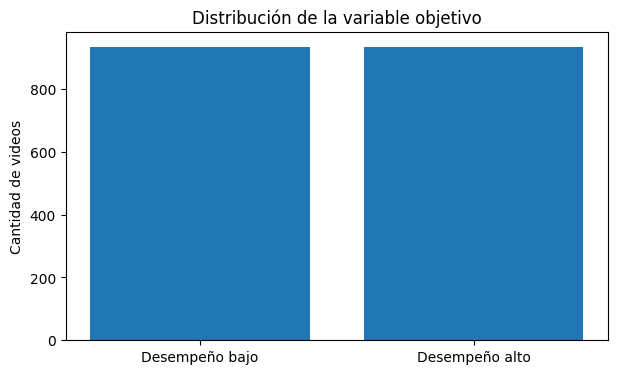

In [ ]:
plt.figure(figsize=(7, 4))

plt.bar(
    df_clases["Clase"],
    df_clases["Cantidad"]
)

plt.title(
    "Distribución de la variable objetivo"
)

plt.ylabel(
    "Cantidad de videos"
)

plt.show()

### Variable objetivo

El desempeño fue dividido en dos categorías utilizando la mediana de Views.

Los videos con un número de visualizaciones inferior a la mediana fueron clasificados como desempeño bajo, mientras que aquellos con visualizaciones iguales o superiores fueron clasificados como desempeño alto.

Esta estrategia produce clases aproximadamente balanceadas y evita que los videos extremadamente virales definan el límite de clasificación.

In [ ]:
variables_numericas_nlp = [

    "Log_Comment_Likes_Mean",

    "Positive_Ratio",

    "Negative_Ratio",

    "Avg_Comment_Words"
]

variable_texto = "Comments_Text"

X = datos_nlp[
    [variable_texto] +
    variables_numericas_nlp
].copy()

y = datos_nlp[
    "Performance"
].copy()

print("Variables utilizadas:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print("Performance")

display(X.head())

Variables utilizadas:
['Comments_Text', 'Log_Comment_Likes_Mean', 'Positive_Ratio', 'Negative_Ratio', 'Avg_Comment_Words']

Variable objetivo:
Performance


,Comments_Text,Log_Comment_Likes_Mean,Positive_Ratio,Negative_Ratio,Avg_Comment_Words
0,let s not forget that apple pay in required a ...,3.691376,0.4,0.2,38.1
1,wow you really went to town on the psu test ra...,6.395595,0.9,0.1,45.5
2,linus just turn the key lights and bounce them...,6.441265,0.9,0.0,30.6
3,unstoppable experiments with liquid nitrogen o...,6.272500,0.6,0.0,9.6
4,guys a quick note that you do not need all the...,7.909379,0.6,0.0,78.3


In [ ]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

X_train, X_test, y_train, y_test = (
    train_test_split(

        X,
        y,

        test_size=0.20,

        random_state=42,

        stratify=y
    )
)

print(
    "Registros de entrenamiento:",
    len(X_train)
)

print(
    "Registros de prueba:",
    len(X_test)
)

print("\nDistribución entrenamiento:")

print(
    y_train.value_counts(
        normalize=True
    )
)

Registros de entrenamiento: 1493
Registros de prueba: 374

Distribución entrenamiento:
Performance
1    0.500335
0    0.499665
Name: proportion, dtype: float64


## 8. División de los datos

El 80 % de los registros se utilizará para entrenamiento y el 20 % para evaluación final.

Se aplicó una división estratificada para conservar aproximadamente la misma proporción de videos con desempeño alto y bajo en ambos conjuntos.

In [ ]:
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.compose import (
    ColumnTransformer
)

from sklearn.pipeline import (
    Pipeline
)

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.impute import (
    SimpleImputer
)

# Stopwords manteniendo palabras de negación
# importantes para el análisis de sentimiento.
stopwords_nlp = list(
    ENGLISH_STOP_WORDS -
    {
        "not",
        "no",
        "never",
        "nor"
    }
)

print("Cantidad de stopwords utilizadas:")
print(len(stopwords_nlp))

print("\nNegaciones conservadas:")
print(["not", "no", "never", "nor"])

Cantidad de stopwords utilizadas:
314

Negaciones conservadas:
['not', 'no', 'never', 'nor']


## 9. Representación del texto mediante TF-IDF

Los algoritmos de Machine Learning no pueden trabajar directamente con texto.

Por esta razón, los comentarios serán convertidos a vectores numéricos utilizando **TF-IDF (Term Frequency - Inverse Document Frequency)**.

TF-IDF permite aumentar la importancia de términos relevantes dentro de un documento y disminuir el peso de palabras demasiado frecuentes.

Se utilizarán unigramas y bigramas para capturar tanto palabras individuales como combinaciones de dos palabras.

In [ ]:
procesador_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [ ]:
preprocesador_combinado = (
    ColumnTransformer(
        transformers=[

            (
                "text",

                TfidfVectorizer(
                    max_features=3000,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.95,
                   stop_words=stopwords_nlp,
                    sublinear_tf=True
                ),

                "Comments_Text"
            ),

            (
                "num",
                procesador_numerico,
                variables_numericas_nlp
            )
        ]
    )
)

print(
    "Preprocesador NLP creado correctamente."
)

Preprocesador NLP creado correctamente.


In [ ]:
from sklearn.linear_model import (
    LogisticRegression
)

In [ ]:
preprocesador_texto = (
    ColumnTransformer(
        transformers=[
            (
                "text",

                TfidfVectorizer(
                    max_features=3000,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.95,
                    stop_words=stopwords_nlp,
                    sublinear_tf=True
                ),

                "Comments_Text"
            )
        ]
    )
)


preprocesador_estadistico = (
    ColumnTransformer(
        transformers=[
            (
                "num",
                procesador_numerico,
                variables_numericas_nlp
            )
        ]
    )
)

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

configuraciones = {

    "Solo TF-IDF":
        preprocesador_texto,

    "Solo estadísticas":
        preprocesador_estadistico,

    "TF-IDF + estadísticas":
        preprocesador_combinado
}

resultados_configuracion = []

for nombre, procesador in configuraciones.items():

    pipeline_config = Pipeline(
        steps=[
            (
                "preprocesamiento",
                procesador
            ),

            (
                "modelo",
                LogisticRegression(
                    max_iter=3000
                )
            )
        ]
    )

    scores = cross_validate(
        pipeline_config,

        X_train,
        y_train,

        cv=cv,

        scoring={
            "Accuracy": "accuracy",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },

        n_jobs=-1
    )

    resultados_configuracion.append({

        "Configuración":
            nombre,

        "Accuracy":
            scores[
                "test_Accuracy"
            ].mean(),

        "F1":
            scores[
                "test_F1"
            ].mean(),

        "ROC-AUC":
            scores[
                "test_ROC_AUC"
            ].mean()
    })


df_configuraciones = pd.DataFrame(
    resultados_configuracion
)

df_configuraciones

,Configuración,Accuracy,F1,ROC-AUC
0,Solo TF-IDF,0.718693,0.726519,0.787419
1,Solo estadísticas,0.793060,0.792566,0.864122
2,TF-IDF + estadísticas,0.817840,0.816804,0.888140


### Comparación de representaciones

Se evaluaron tres configuraciones con el mismo algoritmo para determinar cuánto aporta cada grupo de características.

La primera utiliza únicamente TF-IDF, por lo que representa exclusivamente el contenido textual.

La segunda utiliza solamente variables estadísticas derivadas de los comentarios.

La tercera combina ambas fuentes.

Esta comparación permite determinar si el contenido textual de los comentarios realmente aporta información adicional para predecir el desempeño del video.

In [ ]:
from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier
)

from sklearn.svm import (
    LinearSVC
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

In [ ]:
modelos_nlp = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=3000
        ),

"Linear SVC":
    LinearSVC(
        C=1.0,
        max_iter=20000,
        random_state=42
    ),

    "SGD Classifier":
        SGDClassifier(
            loss="log_loss",
            max_iter=5000,
            tol=1e-4,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=250,
            max_depth=20,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
}

print(
    "Cantidad de modelos evaluados:",
    len(modelos_nlp)
)

for nombre in modelos_nlp:
    print("-", nombre)

Cantidad de modelos evaluados: 5
- Logistic Regression
- Linear SVC
- SGD Classifier
- Random Forest
- Extra Trees


## 10. Comparación de modelos

No se considera suficiente evaluar un único modelo.

Diferentes algoritmos pueden responder de manera distinta ante representaciones textuales de alta dimensionalidad como TF-IDF.

Por esta razón se compararán cinco algoritmos utilizando exactamente los mismos datos y el mismo esquema de validación cruzada.

In [ ]:
resultados_modelos = []

for nombre, modelo in modelos_nlp.items():

    print(
        f"Evaluando: {nombre}"
    )

    pipeline_modelo = Pipeline(
        steps=[

            (
                "preprocesamiento",
                preprocesador_combinado
            ),

            (
                "modelo",
                modelo
            )
        ]
    )

    scores = cross_validate(

        pipeline_modelo,

        X_train,
        y_train,

        cv=cv,

        scoring={
            "Accuracy":
                "accuracy",

            "Precision":
                "precision",

            "Recall":
                "recall",

            "F1":
                "f1",

            "ROC_AUC":
                "roc_auc"
        },

        n_jobs=1
    )

    resultados_modelos.append({

        "Modelo":
            nombre,

        "Accuracy":
            scores[
                "test_Accuracy"
            ].mean(),

        "Precision":
            scores[
                "test_Precision"
            ].mean(),

        "Recall":
            scores[
                "test_Recall"
            ].mean(),

        "F1":
            scores[
                "test_F1"
            ].mean(),

        "ROC-AUC":
            scores[
                "test_ROC_AUC"
            ].mean(),

        "Desv. F1":
            scores[
                "test_F1"
            ].std()
    })


df_modelos_nlp = pd.DataFrame(
    resultados_modelos
)

df_modelos_nlp = (
    df_modelos_nlp
    .sort_values(
        "F1",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

df_modelos_nlp

Evaluando: Logistic Regression
Evaluando: Linear SVC
Evaluando: SGD Classifier
Evaluando: Random Forest
Evaluando: Extra Trees


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Desv. F1
0,Logistic Regression,0.817840,0.822856,0.811293,0.816804,0.888140,0.023676
1,Linear SVC,0.806438,0.810790,0.800564,0.805370,0.887248,0.022386
2,SGD Classifier,0.804435,0.803807,0.807248,0.805249,0.885443,0.023359
3,Random Forest,0.773608,0.757453,0.807275,0.781219,0.852443,0.030972
4,Extra Trees,0.756194,0.722825,0.831391,0.773011,0.840702,0.032373


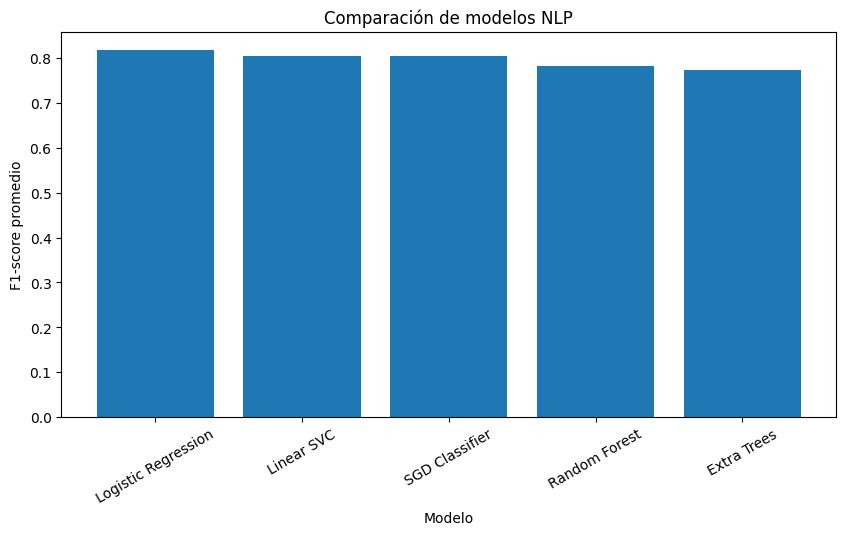

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    df_modelos_nlp["Modelo"],
    df_modelos_nlp["F1"]
)

plt.ylabel(
    "F1-score promedio"
)

plt.xlabel(
    "Modelo"
)

plt.title(
    "Comparación de modelos NLP"
)

plt.xticks(
    rotation=30
)

plt.show()

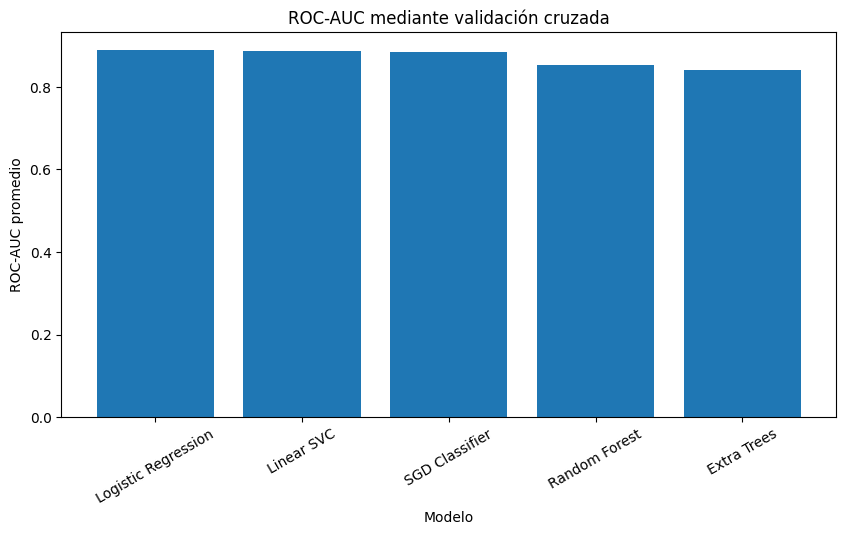

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    df_modelos_nlp["Modelo"],
    df_modelos_nlp["ROC-AUC"]
)

plt.ylabel(
    "ROC-AUC promedio"
)

plt.xlabel(
    "Modelo"
)

plt.title(
    "ROC-AUC mediante validación cruzada"
)

plt.xticks(
    rotation=30
)

plt.show()

### Criterio para seleccionar el modelo

El modelo no se seleccionará únicamente mediante Accuracy.

Debido a que se trata de un problema de clasificación, se analizarán conjuntamente Precision, Recall, F1-score y ROC-AUC.

Se utilizará principalmente F1-score para seleccionar el modelo, ya que combina Precision y Recall en una sola métrica. ROC-AUC se utilizará como medida complementaria de capacidad discriminativa.

In [ ]:
mejor_nombre = (
    df_modelos_nlp
    .iloc[0]["Modelo"]
)

print(
    "Modelo con mayor F1 promedio:"
)

print(mejor_nombre)

display(
    df_modelos_nlp.iloc[[0]]
)

Modelo con mayor F1 promedio:
Logistic Regression


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Desv. F1
0,Logistic Regression,0.81784,0.822856,0.811293,0.816804,0.88814,0.023676


## 11. Optimización del modelo seleccionado

Después de comparar cinco algoritmos mediante validación cruzada, el modelo **Logistic Regression** obtuvo el mayor F1-score promedio.

Por esta razón fue seleccionado para una etapa adicional de optimización.

Se utilizará GridSearchCV para evaluar diferentes valores de regularización y configuración de pesos de clase, manteniendo validación cruzada estratificada de cinco particiones.

El criterio principal de selección será el F1-score.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [ ]:
modelo_logistico = LogisticRegression(
    max_iter=5000,
    random_state=42
)

pipeline_logistico = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_combinado
        ),
        (
            "modelo",
            modelo_logistico
        )
    ]
)

In [ ]:
parametros_logisticos = {

    "modelo__C": [
        0.01,
        0.05,
        0.1,
        0.5,
        1,
        2,
        5,
        10
    ],

    "modelo__class_weight": [
        None,
        "balanced"
    ]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=pipeline_logistico,
    param_grid=parametros_logisticos,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train,
    y_train
)

print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nMejor F1 en validación cruzada:")
print(
    round(
        grid_search.best_score_,
        4
    )
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores hiperparámetros:
{'modelo__C': 5, 'modelo__class_weight': None}

Mejor F1 en validación cruzada:
0.8267


In [ ]:
print("F1 promedio de Logistic Regression original:")

print(
    round(
        df_modelos_nlp.loc[
            df_modelos_nlp["Modelo"] == "Logistic Regression",
            "F1"
        ].iloc[0],
        4
    )
)

print("\nF1 de Logistic Regression optimizado:")

print(
    round(
        grid_search.best_score_,
        4
    )
)

F1 promedio de Logistic Regression original:
0.8168

F1 de Logistic Regression optimizado:
0.8267


### Resultado de la optimización

La optimización permite determinar si una configuración diferente de hiperparámetros mejora el desempeño de Logistic Regression.

La comparación utiliza el mismo F1-score y esquema de validación cruzada empleados durante la selección inicial.

Esto permite evaluar si el modelo seleccionado puede mejorar su capacidad de clasificación mediante un ajuste de regularización y pesos de clase.

In [ ]:
mejor_modelo_final = grid_search.best_estimator_

predicciones = mejor_modelo_final.predict(
    X_test
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [ ]:
accuracy = accuracy_score(
    y_test,
    predicciones
)

precision = precision_score(
    y_test,
    predicciones
)

recall = recall_score(
    y_test,
    predicciones
)

f1 = f1_score(
    y_test,
    predicciones
)

# Logistic Regression permite obtener
# probabilidades de pertenencia a cada clase
probabilidades = (
    mejor_modelo_final
    .predict_proba(X_test)[:, 1]
)

roc_auc = roc_auc_score(
    y_test,
    probabilidades
)

In [ ]:
df_metricas_finales = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Resultado": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

df_metricas_finales["Resultado"] = (
    df_metricas_finales["Resultado"]
    .round(4)
)

df_metricas_finales

,Métrica,Resultado
0,Accuracy,0.8235
1,Precision,0.8235
2,Recall,0.8235
3,F1-score,0.8235
4,ROC-AUC,0.8969


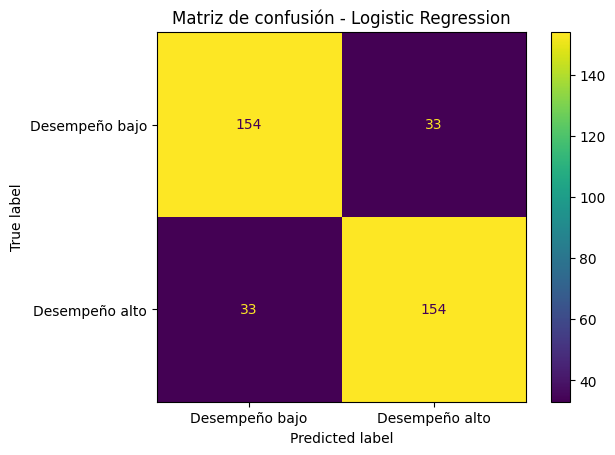

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones,
    display_labels=[
        "Desempeño bajo",
        "Desempeño alto"
    ]
)
plt.title(
    "Matriz de confusión - Logistic Regression"
)

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        predicciones,
        target_names=[
            "Desempeño bajo",
            "Desempeño alto"
        ]
    )
)

                precision    recall  f1-score   support

Desempeño bajo       0.82      0.82      0.82       187
Desempeño alto       0.82      0.82      0.82       187

      accuracy                           0.82       374
     macro avg       0.82      0.82      0.82       374
  weighted avg       0.82      0.82      0.82       374



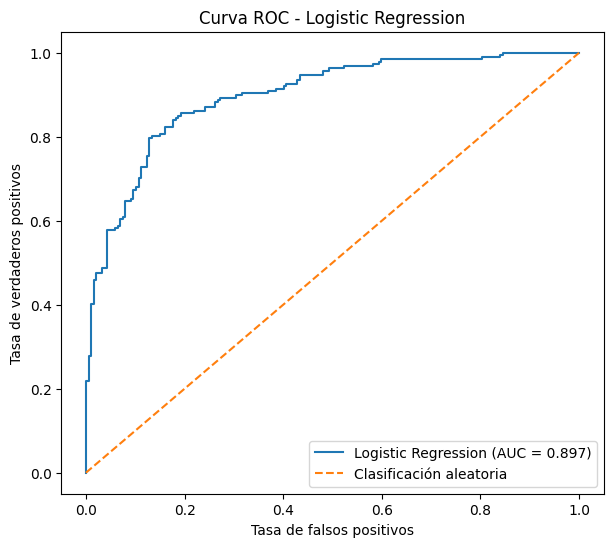

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    probabilidades
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificación aleatoria"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")

plt.title(
    "Curva ROC - Logistic Regression"
)

plt.legend()
plt.show()


In [ ]:
preprocesador_final = (
    mejor_modelo_final
    .named_steps["preprocesamiento"]
)

modelo_final = (
    mejor_modelo_final
    .named_steps["modelo"]
)


In [ ]:
nombres_features = (
    preprocesador_final
    .get_feature_names_out()
)

print("Cantidad total de características:")
print(len(nombres_features))


Cantidad total de características:
3004


In [ ]:
coeficientes = (
    modelo_final
    .coef_[0]
)

df_coeficientes = pd.DataFrame({
    "Variable": nombres_features,
    "Coeficiente": coeficientes
})


In [ ]:
print(
    "CARACTERÍSTICAS ASOCIADAS A DESEMPEÑO ALTO:"
)

display(
    df_coeficientes
    .sort_values(
        "Coeficiente",
        ascending=False
    )
    .head(20)
)


CARACTERÍSTICAS ASOCIADAS A DESEMPEÑO ALTO:


,Variable,Coeficiente
877,text__explanation,2.834121
92,text__animals,2.503969
531,text__cube,2.472195
193,text__bed,2.467119
170,text__ball,2.377924
162,text__awesome,2.302140
1076,text__good work,2.289560
2999,text__zoom,2.227081
1955,text__physics,2.176499
3000,num__Log_Comment_Likes_Mean,2.167450


In [ ]:
print(
    "CARACTERÍSTICAS ASOCIADAS A DESEMPEÑO BAJO:"
)

display(
    df_coeficientes
    .sort_values(
        "Coeficiente",
        ascending=True
    )
    .head(20)
)


CARACTERÍSTICAS ASOCIADAS A DESEMPEÑO BAJO:


,Variable,Coeficiente
2278,text__sat,-3.460897
2596,text__talking,-2.865591
1282,text__insane,-2.448143
141,text__asmr,-2.296975
1586,text__magnus,-2.292548
1154,text__hearing,-2.240328
1055,text__giving,-2.097523
244,text__books,-2.075190
2143,text__reactions,-2.018453
1220,text__hrithik,-2.002977


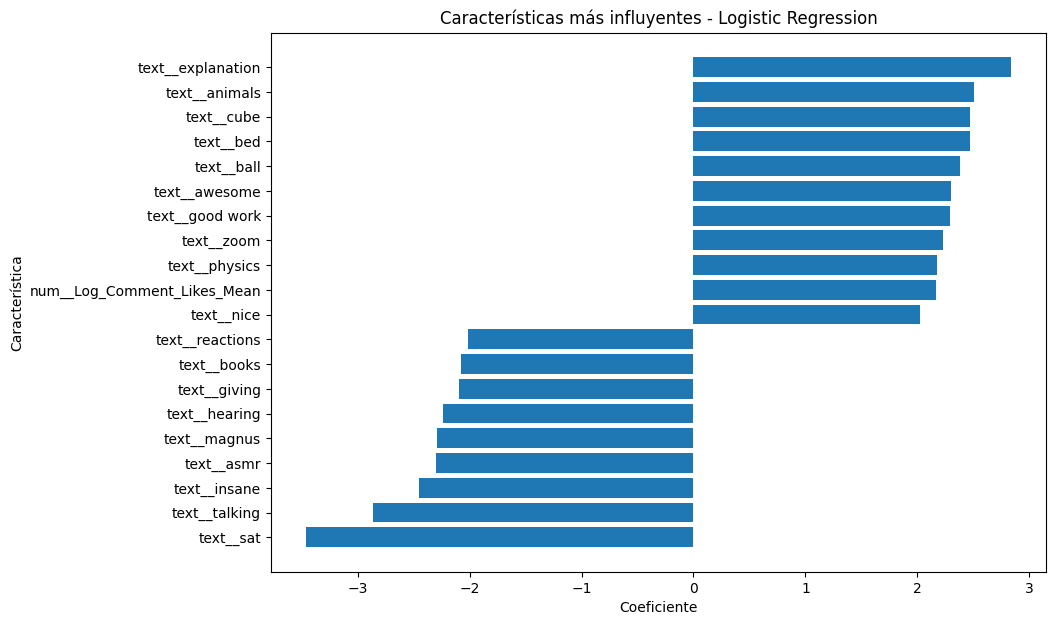

In [ ]:
df_coeficientes["Importancia_Absoluta"] = (
    df_coeficientes[
        "Coeficiente"
    ].abs()
)

top_coeficientes = (
    df_coeficientes
    .sort_values(
        "Importancia_Absoluta",
        ascending=False
    )
    .head(20)
    .sort_values(
        "Coeficiente"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_coeficientes["Variable"],
    top_coeficientes["Coeficiente"]
)

plt.xlabel("Coeficiente")
plt.ylabel("Característica")

plt.title(
    "Características más influyentes - Logistic Regression"
)

plt.show()


In [ ]:
import joblib

artefacto_modelo = {

    "modelo":
        mejor_modelo_final,

    "umbral_views":
        umbral_views,

    "modelo_nombre":
        "Logistic Regression",

    "descripcion":
        "Modelo NLP para predecir desempeño de videos de YouTube mediante comentarios"
}

ruta_modelo = (
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "modelo_nlp_youtube_logistic_regression.pkl"
)

joblib.dump(
    artefacto_modelo,
    ruta_modelo
)

print("Modelo guardado correctamente:")
print(ruta_modelo)


Modelo guardado correctamente:
/content/drive/MyDrive/Colab Notebooks/modelo_nlp_youtube_logistic_regression.pkl


# Avance III - Semana 9
## Iteración de algoritmos NLP y análisis de sentimiento

En el Avance II se construyó un modelo NLP para clasificar el desempeño de videos de YouTube utilizando información proveniente de sus comentarios.

El mejor algoritmo fue Logistic Regression, utilizando una combinación de TF-IDF y variables estadísticas derivadas de los comentarios.

Resultados de referencia del Avance II:

- F1 de validación antes de optimización: 0.8168
- F1 después de GridSearchCV: 0.8267
- Accuracy en prueba: 0.8235
- Precision en prueba: 0.8235
- Recall en prueba: 0.8235
- F1-score en prueba: 0.8235
- ROC-AUC en prueba: 0.8969

En la Semana 9 se profundizará en los algoritmos NLP utilizados como parte de la solución.

Se desarrollará un componente propio de análisis de sentimiento y se compararán diferentes algoritmos para determinar cuál identifica mejor comentarios positivos, neutrales y negativos.

Posteriormente, las predicciones de sentimiento se utilizarán como nuevas características del modelo de desempeño.

In [ ]:
baseline_avance2 = pd.DataFrame({
    "Modelo": ["Logistic Regression - Avance II"],
    "F1_CV": [0.8267],
    "Accuracy_Test": [0.8235],
    "F1_Test": [0.8235],
    "ROC_AUC_Test": [0.8969]
})

print("MODELO DE REFERENCIA DEL AVANCE II")
display(baseline_avance2)

MODELO DE REFERENCIA DEL AVANCE II


,Modelo,F1_CV,Accuracy_Test,F1_Test,ROC_AUC_Test
0,Logistic Regression - Avance II,0.8267,0.8235,0.8235,0.8969


## 14. Componente de análisis de sentimiento

El dataset original contiene una variable `Sentiment` asociada a cada comentario:

- 0 = Negativo
- 1 = Neutral
- 2 = Positivo

En el avance anterior esta variable fue utilizada directamente para calcular proporciones de sentimiento por video.

En esta nueva iteración se utilizarán estas etiquetas como datos de entrenamiento para construir un modelo NLP capaz de determinar automáticamente el sentimiento de un comentario a partir de su contenido textual.

Esto permite que el sistema final no dependa de que el usuario proporcione manualmente una etiqueta de sentimiento.

In [ ]:
# Crear dataset específico para análisis de sentimiento

datos_sentimiento = comments_nlp[
    [
        "Video ID",
        "Comment",
        "Comment_Clean",
        "Sentiment"
    ]
].copy()

# Eliminar registros sin información necesaria
datos_sentimiento = datos_sentimiento.dropna(
    subset=[
        "Comment_Clean",
        "Sentiment",
        "Video ID"
    ]
)

# Conservar únicamente las clases válidas
datos_sentimiento = datos_sentimiento[
    datos_sentimiento["Sentiment"].isin([0, 1, 2])
].copy()

# Convertir a entero
datos_sentimiento["Sentiment"] = (
    datos_sentimiento["Sentiment"]
    .astype(int)
)

print("Cantidad de comentarios disponibles:")
print(len(datos_sentimiento))

print("\nCantidad de videos:")
print(
    datos_sentimiento["Video ID"].nunique()
)

print("\nDistribución de sentimientos:")

distribucion_sentimiento = (
    datos_sentimiento["Sentiment"]
    .value_counts()
    .sort_index()
)

print(distribucion_sentimiento)

print("\nDistribución porcentual:")

print(
    (
        datos_sentimiento["Sentiment"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

Cantidad de comentarios disponibles:
18260

Cantidad de videos:
1869

Distribución de sentimientos:
Sentiment
0     2332
1     4610
2    11318
Name: count, dtype: int64

Distribución porcentual:
Sentiment
0    12.77
1    25.25
2    61.98
Name: proportion, dtype: float64


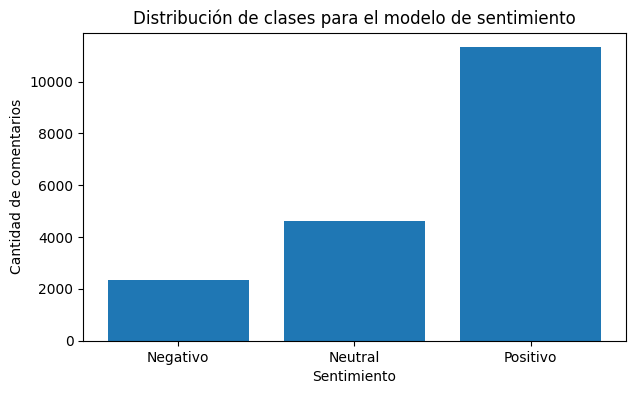

In [ ]:
nombres_sentimiento = {
    0: "Negativo",
    1: "Neutral",
    2: "Positivo"
}

conteo_sentimiento = (
    datos_sentimiento["Sentiment"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 4))

plt.bar(
    [
        nombres_sentimiento[i]
        for i in conteo_sentimiento.index
    ],
    conteo_sentimiento.values
)

plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de comentarios")

plt.title(
    "Distribución de clases para el modelo de sentimiento"
)

plt.show()

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

X_sentimiento = (
    datos_sentimiento["Comment_Clean"]
)

y_sentimiento = (
    datos_sentimiento["Sentiment"]
)

grupos_sentimiento = (
    datos_sentimiento["Video ID"]
)

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(
        X_sentimiento,
        y_sentimiento,
        groups=grupos_sentimiento
    )
)

X_sent_train = X_sentimiento.iloc[train_idx]
X_sent_test = X_sentimiento.iloc[test_idx]

y_sent_train = y_sentimiento.iloc[train_idx]
y_sent_test = y_sentimiento.iloc[test_idx]

groups_sent_train = grupos_sentimiento.iloc[train_idx]
groups_sent_test = grupos_sentimiento.iloc[test_idx]

print("Comentarios de entrenamiento:")
print(len(X_sent_train))

print("\nComentarios de prueba:")
print(len(X_sent_test))

print("\nVideos únicos de entrenamiento:")
print(groups_sent_train.nunique())

print("\nVideos únicos de prueba:")
print(groups_sent_test.nunique())

# Verificar fuga
videos_train = set(groups_sent_train)
videos_test = set(groups_sent_test)

print("\nVideos presentes simultáneamente en train y test:")
print(
    len(
        videos_train.intersection(
            videos_test
        )
    )
)

Comentarios de entrenamiento:
14604

Comentarios de prueba:
3656

Videos únicos de entrenamiento:
1495

Videos únicos de prueba:
374

Videos presentes simultáneamente en train y test:
0


## 15. Comparación de algoritmos para Sentiment Analysis

Para construir el componente de análisis de sentimiento se evaluarán cuatro algoritmos clásicos utilizados en clasificación de texto:

1. Logistic Regression.
2. Linear Support Vector Classifier.
3. SGD Classifier.
4. Multinomial Naive Bayes.

Todos los modelos recibirán exactamente la misma representación TF-IDF.

La comparación se realizará mediante validación cruzada y utilizando principalmente Macro F1, debido a que las clases de sentimiento no están perfectamente balanceadas.

In [ ]:
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier
)

from sklearn.svm import LinearSVC

from sklearn.naive_bayes import (
    MultinomialNB
)

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

# Mantener negaciones importantes
stopwords_sentimiento = list(
    ENGLISH_STOP_WORDS -
    {
        "not",
        "no",
        "never",
        "nor"
    }
)

modelos_sentimiento = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000,
            random_state=42
        ),

    "Linear SVC":
        LinearSVC(
            C=1.0,
            max_iter=20000,
            random_state=42
        ),

    "SGD Classifier":
        SGDClassifier(
            loss="log_loss",
            max_iter=5000,
            tol=1e-4,
            random_state=42
        ),

    "Multinomial Naive Bayes":
        MultinomialNB(
            alpha=1.0
        )
}

print(
    "Modelos de sentimiento a evaluar:",
    len(modelos_sentimiento)
)

for nombre in modelos_sentimiento:
    print("-", nombre)

Modelos de sentimiento a evaluar: 4
- Logistic Regression
- Linear SVC
- SGD Classifier
- Multinomial Naive Bayes


In [ ]:
cv_sentimiento = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados_sentimiento = []

for nombre, modelo in modelos_sentimiento.items():

    print(
        f"Evaluando: {nombre}"
    )

    pipeline_sentimiento = Pipeline(
        steps=[
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.95,
                    stop_words=stopwords_sentimiento,
                    sublinear_tf=True
                )
            ),
            (
                "modelo",
                modelo
            )
        ]
    )

    scores = cross_validate(
        pipeline_sentimiento,
        X_sent_train,
        y_sent_train,
        groups=groups_sent_train,
        cv=cv_sentimiento,
        scoring={
            "Accuracy":
                "accuracy",

            "Balanced_Accuracy":
                "balanced_accuracy",

            "Precision_Macro":
                "precision_macro",

            "Recall_Macro":
                "recall_macro",

            "F1_Macro":
                "f1_macro"
        },
        n_jobs=-1
    )

    resultados_sentimiento.append({

        "Modelo":
            nombre,

        "Accuracy":
            scores[
                "test_Accuracy"
            ].mean(),

        "Balanced Accuracy":
            scores[
                "test_Balanced_Accuracy"
            ].mean(),

        "Precision Macro":
            scores[
                "test_Precision_Macro"
            ].mean(),

        "Recall Macro":
            scores[
                "test_Recall_Macro"
            ].mean(),

        "F1 Macro":
            scores[
                "test_F1_Macro"
            ].mean(),

        "Desv. F1":
            scores[
                "test_F1_Macro"
            ].std()
    })


df_modelos_sentimiento = pd.DataFrame(
    resultados_sentimiento
)

df_modelos_sentimiento = (
    df_modelos_sentimiento
    .sort_values(
        "F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    df_modelos_sentimiento.round(4)
)

Evaluando: Logistic Regression
Evaluando: Linear SVC
Evaluando: SGD Classifier
Evaluando: Multinomial Naive Bayes


,Modelo,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,Desv. F1
0,Linear SVC,0.7278,0.6075,0.6355,0.6075,0.6182,0.0105
1,Logistic Regression,0.7388,0.5852,0.6707,0.5852,0.6062,0.0081
2,SGD Classifier,0.7268,0.5466,0.6827,0.5466,0.5702,0.0208
3,Multinomial Naive Bayes,0.6756,0.4448,0.6858,0.4448,0.4548,0.0127


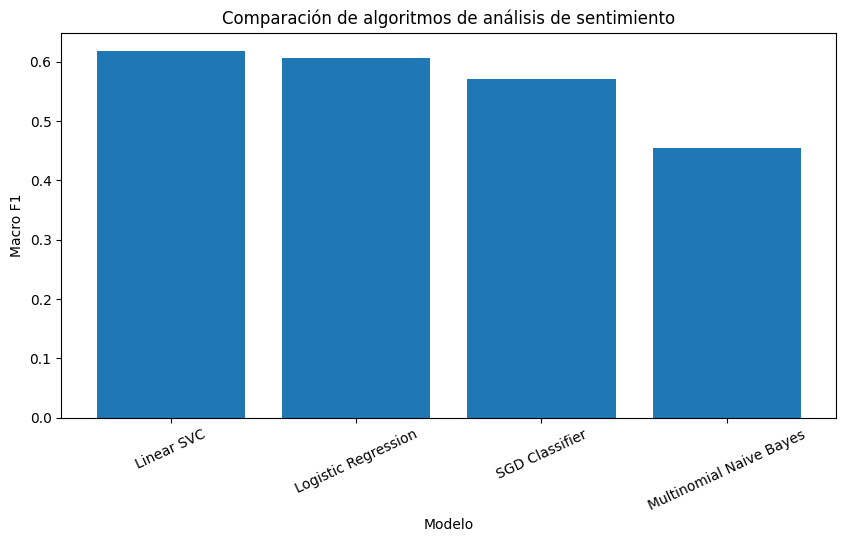

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    df_modelos_sentimiento["Modelo"],
    df_modelos_sentimiento["F1 Macro"]
)

plt.xlabel("Modelo")
plt.ylabel("Macro F1")

plt.title(
    "Comparación de algoritmos de análisis de sentimiento"
)

plt.xticks(
    rotation=25
)

plt.show()

In [ ]:
mejor_modelo_sentimiento = (
    df_modelos_sentimiento
    .iloc[0]["Modelo"]
)

mejor_f1_sentimiento = (
    df_modelos_sentimiento
    .iloc[0]["F1 Macro"]
)

print(
    "MODELO GANADOR PARA ANÁLISIS DE SENTIMIENTO:"
)

print(
    mejor_modelo_sentimiento
)

print(
    "\nMacro F1 promedio:"
)

print(
    round(
        mejor_f1_sentimiento,
        4
    )
)

print(
    "\nResultados completos:"
)

display(
    df_modelos_sentimiento
    .iloc[[0]]
    .round(4)
)

MODELO GANADOR PARA ANÁLISIS DE SENTIMIENTO:
Linear SVC

Macro F1 promedio:
0.6182

Resultados completos:


,Modelo,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,Desv. F1
0,Linear SVC,0.7278,0.6075,0.6355,0.6075,0.6182,0.0105


## 16. Iteración 2 - Optimización del modelo de sentimiento

En la primera comparación se evaluaron cuatro algoritmos de clasificación de texto.

Linear SVC obtuvo el mejor Macro F1 promedio:

- Accuracy: 0.7278
- Balanced Accuracy: 0.6075
- Macro F1: 0.6182
- Desviación estándar de F1: 0.0105

Aunque Logistic Regression obtuvo una Accuracy ligeramente superior, Linear SVC presentó el mejor Macro F1 y Balanced Accuracy. Debido al desbalance existente entre las clases de sentimiento, se mantiene Macro F1 como criterio principal de selección.

En esta segunda iteración se optimizarán simultáneamente parámetros de la representación TF-IDF y del algoritmo Linear SVC mediante GridSearchCV.

El conjunto de prueba permanecerá completamente separado durante esta optimización.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

pipeline_svc_sentimiento = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                min_df=2,
                max_df=0.95,
                stop_words=stopwords_sentimiento,
                sublinear_tf=True
            )
        ),
        (
            "modelo",
            LinearSVC(
                max_iter=20000,
                random_state=42
            )
        )
    ]
)

print("Pipeline de optimización creado correctamente.")

Pipeline de optimización creado correctamente.


In [ ]:
param_grid_sentimiento = {

    "tfidf__max_features": [
        3000,
        5000
    ],

    "tfidf__ngram_range": [
        (1, 1),
        (1, 2)
    ],

    "modelo__C": [
        0.25,
        0.5,
        1.0,
        2.0
    ],

    "modelo__class_weight": [
        None,
        "balanced"
    ]
}

total_combinaciones = (
    len(param_grid_sentimiento["tfidf__max_features"])
    * len(param_grid_sentimiento["tfidf__ngram_range"])
    * len(param_grid_sentimiento["modelo__C"])
    * len(param_grid_sentimiento["modelo__class_weight"])
)

print("Cantidad de combinaciones:")
print(total_combinaciones)

print("\nCon validación cruzada de 5 folds:")
print(total_combinaciones * 5, "ajustes")

Cantidad de combinaciones:
32

Con validación cruzada de 5 folds:
160 ajustes


In [ ]:
from sklearn.model_selection import GridSearchCV

grid_sentimiento = GridSearchCV(
    estimator=pipeline_svc_sentimiento,
    param_grid=param_grid_sentimiento,
    scoring="f1_macro",
    cv=cv_sentimiento,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_sentimiento.fit(
    X_sent_train,
    y_sent_train,
    groups=groups_sent_train
)

print("\nMEJORES HIPERPARÁMETROS")
print(grid_sentimiento.best_params_)

print("\nMEJOR MACRO F1 EN VALIDACIÓN CRUZADA")
print(
    round(
        grid_sentimiento.best_score_,
        4
    )
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits

MEJORES HIPERPARÁMETROS
{'modelo__C': 0.25, 'modelo__class_weight': 'balanced', 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}

MEJOR MACRO F1 EN VALIDACIÓN CRUZADA
0.6478


In [ ]:
f1_svc_inicial = 0.6182
f1_svc_optimizado = grid_sentimiento.best_score_

mejora_absoluta = (
    f1_svc_optimizado
    - f1_svc_inicial
)

mejora_porcentual = (
    mejora_absoluta
    / f1_svc_inicial
) * 100

comparacion_iteracion = pd.DataFrame({
    "Versión": [
        "Linear SVC inicial",
        "Linear SVC optimizado"
    ],
    "Macro F1 CV": [
        f1_svc_inicial,
        f1_svc_optimizado
    ]
})

display(
    comparacion_iteracion.round(4)
)

print(
    "\nMejora absoluta:",
    round(mejora_absoluta, 4)
)

print(
    "Mejora porcentual:",
    round(mejora_porcentual, 2),
    "%"
)

,Versión,Macro F1 CV
0,Linear SVC inicial,0.6182
1,Linear SVC optimizado,0.6478



Mejora absoluta: 0.0296
Mejora porcentual: 4.79 %


In [ ]:
resultados_grid_sentimiento = pd.DataFrame(
    grid_sentimiento.cv_results_
)

columnas_resultados = [
    "param_tfidf__max_features",
    "param_tfidf__ngram_range",
    "param_modelo__C",
    "param_modelo__class_weight",
    "mean_test_score",
    "std_test_score",
    "mean_train_score"
]

top_configuraciones_sentimiento = (
    resultados_grid_sentimiento[
        columnas_resultados
    ]
    .sort_values(
        "mean_test_score",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_configuraciones_sentimiento.columns = [
    "Max Features",
    "N-gramas",
    "C",
    "Class Weight",
    "Macro F1 CV",
    "Desv. F1",
    "Macro F1 Train"
]

display(
    top_configuraciones_sentimiento.round(4)
)

,Max Features,N-gramas,C,Class Weight,Macro F1 CV,Desv. F1,Macro F1 Train
0,5000,"(1, 1)",0.25,balanced,0.6478,0.0123,0.8659
1,5000,"(1, 2)",0.25,balanced,0.6449,0.0092,0.8602
2,3000,"(1, 1)",0.25,balanced,0.6418,0.0130,0.8232
3,5000,"(1, 2)",0.50,balanced,0.6388,0.0112,0.8872
4,5000,"(1, 1)",0.50,balanced,0.6349,0.0114,0.8945
5,3000,"(1, 2)",0.25,balanced,0.6338,0.0132,0.8159
6,3000,"(1, 1)",0.50,balanced,0.6325,0.0141,0.8438
7,3000,"(1, 2)",0.50,balanced,0.6298,0.0159,0.8356
8,5000,"(1, 2)",1.00,balanced,0.6283,0.0133,0.9131
9,5000,"(1, 1)",1.00,balanced,0.6258,0.0117,0.9193


## 17. Evaluación independiente del modelo de sentimiento

Una vez seleccionada la mejor configuración mediante validación cruzada, el modelo se evaluará sobre el conjunto de prueba reservado anteriormente.

Este conjunto contiene comentarios pertenecientes a videos que no estuvieron presentes durante el entrenamiento ni durante la optimización.

Las métricas utilizadas serán:

- Accuracy
- Balanced Accuracy
- Precision Macro
- Recall Macro
- Macro F1

También se analizará la matriz de confusión y el reporte de clasificación para identificar posibles diferencias de desempeño entre sentimientos negativos, neutrales y positivos.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

mejor_modelo_sentimiento_final = (
    grid_sentimiento.best_estimator_
)

pred_sent_test = (
    mejor_modelo_sentimiento_final
    .predict(X_sent_test)
)

accuracy_sent = accuracy_score(
    y_sent_test,
    pred_sent_test
)

balanced_accuracy_sent = balanced_accuracy_score(
    y_sent_test,
    pred_sent_test
)

precision_macro_sent = precision_score(
    y_sent_test,
    pred_sent_test,
    average="macro",
    zero_division=0
)

recall_macro_sent = recall_score(
    y_sent_test,
    pred_sent_test,
    average="macro",
    zero_division=0
)

f1_macro_sent = f1_score(
    y_sent_test,
    pred_sent_test,
    average="macro",
    zero_division=0
)

metricas_sentimiento_test = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Resultado": [
        accuracy_sent,
        balanced_accuracy_sent,
        precision_macro_sent,
        recall_macro_sent,
        f1_macro_sent
    ]
})

print(
    "RESULTADOS DEL MODELO DE SENTIMIENTO EN PRUEBA"
)

display(
    metricas_sentimiento_test.round(4)
)

RESULTADOS DEL MODELO DE SENTIMIENTO EN PRUEBA


,Métrica,Resultado
0,Accuracy,0.7309
1,Balanced Accuracy,0.6563
2,Precision Macro,0.6405
3,Recall Macro,0.6563
4,F1 Macro,0.6471


In [ ]:
print(
    classification_report(
        y_sent_test,
        pred_sent_test,
        labels=[0, 1, 2],
        target_names=[
            "Negativo",
            "Neutral",
            "Positivo"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negativo     0.4923    0.5246    0.5079       488
     Neutral     0.5556    0.6285    0.5898       899
    Positivo     0.8735    0.8158    0.8437      2269

    accuracy                         0.7309      3656
   macro avg     0.6405    0.6563    0.6471      3656
weighted avg     0.7445    0.7309    0.7364      3656



<Figure size 700x600 with 0 Axes>

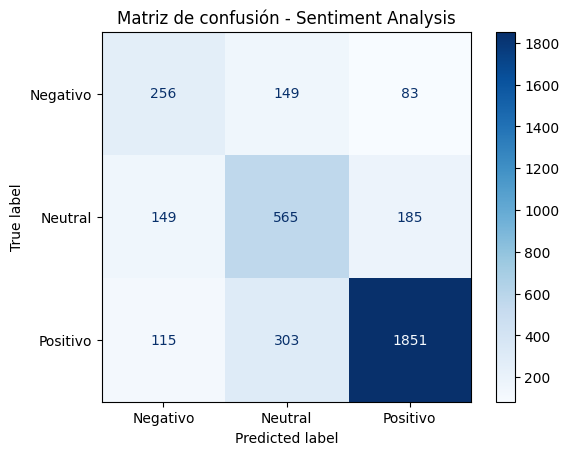

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_sent_test,
    pred_sent_test,
    labels=[0, 1, 2],
    display_labels=[
        "Negativo",
        "Neutral",
        "Positivo"
    ],
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Matriz de confusión - Sentiment Analysis"
)

plt.show()

In [ ]:
print("RESUMEN DE LA ITERACIÓN DE SENTIMIENTO")
print("-" * 50)

print(
    "Modelo seleccionado:",
    mejor_modelo_sentimiento
)

print(
    "Macro F1 inicial CV:",
    round(f1_svc_inicial, 4)
)

print(
    "Macro F1 optimizado CV:",
    round(f1_svc_optimizado, 4)
)

print(
    "Macro F1 en prueba:",
    round(f1_macro_sent, 4)
)

print(
    "Balanced Accuracy en prueba:",
    round(balanced_accuracy_sent, 4)
)

print("\nMejores parámetros:")

for parametro, valor in (
    grid_sentimiento
    .best_params_
    .items()
):
    print(
        f"{parametro}: {valor}"
    )

RESUMEN DE LA ITERACIÓN DE SENTIMIENTO
--------------------------------------------------
Modelo seleccionado: Linear SVC
Macro F1 inicial CV: 0.6182
Macro F1 optimizado CV: 0.6478
Macro F1 en prueba: 0.6471
Balanced Accuracy en prueba: 0.6563

Mejores parámetros:
modelo__C: 0.25
modelo__class_weight: balanced
tfidf__max_features: 5000
tfidf__ngram_range: (1, 1)


## 18. Integración del modelo automático de sentimiento

Hasta este punto, el modelo de desempeño utilizaba las variables `Positive_Ratio` y `Negative_Ratio` calculadas directamente a partir de la etiqueta `Sentiment` incluida en el dataset original.

Sin embargo, en un escenario real un usuario proporcionaría comentarios de YouTube, pero no necesariamente conocería previamente el sentimiento de cada comentario.

Por esta razón, en esta iteración se sustituirán las etiquetas de sentimiento originales por predicciones generadas automáticamente mediante el modelo Linear SVC optimizado.

Para evitar fuga de información:

- Los videos utilizados para prueba del modelo de desempeño permanecerán separados.
- En los videos de entrenamiento se generarán predicciones de sentimiento fuera de muestra mediante validación cruzada agrupada.
- El modelo de sentimiento entrenado con los videos de entrenamiento será utilizado para predecir los comentarios de los videos de prueba.

Esto permite evaluar una arquitectura más cercana a un sistema NLP desplegable en un entorno real.

In [ ]:
# Identificar los Video ID correspondientes
# a la división original del modelo de desempeño

videos_train_performance = set(
    datos_nlp.loc[
        X_train.index,
        "Video ID"
    ]
)

videos_test_performance = set(
    datos_nlp.loc[
        X_test.index,
        "Video ID"
    ]
)

print(
    "Videos de entrenamiento del modelo de desempeño:",
    len(videos_train_performance)
)

print(
    "Videos de prueba del modelo de desempeño:",
    len(videos_test_performance)
)

print(
    "\nVideos presentes simultáneamente en ambos conjuntos:"
)

print(
    len(
        videos_train_performance.intersection(
            videos_test_performance
        )
    )
)

Videos de entrenamiento del modelo de desempeño: 1493
Videos de prueba del modelo de desempeño: 374

Videos presentes simultáneamente en ambos conjuntos:
0


In [ ]:
sentimiento_train_performance = (
    datos_sentimiento[
        datos_sentimiento["Video ID"].isin(
            videos_train_performance
        )
    ]
    .copy()
    .reset_index(drop=True)
)

sentimiento_test_performance = (
    datos_sentimiento[
        datos_sentimiento["Video ID"].isin(
            videos_test_performance
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Comentarios para entrenamiento:")
print(len(sentimiento_train_performance))

print("\nComentarios para prueba:")
print(len(sentimiento_test_performance))

print("\nVideos únicos de entrenamiento:")
print(
    sentimiento_train_performance[
        "Video ID"
    ].nunique()
)

print("\nVideos únicos de prueba:")
print(
    sentimiento_test_performance[
        "Video ID"
    ].nunique()
)

Comentarios para entrenamiento:
14624

Comentarios para prueba:
3616

Videos únicos de entrenamiento:
1493

Videos únicos de prueba:
374


### Predicciones de sentimiento Out-of-Fold

Para construir las variables de sentimiento de los videos utilizados durante el entrenamiento del modelo principal no se usarán predicciones realizadas sobre los mismos comentarios utilizados para entrenar el clasificador.

Se aplicará `StratifiedGroupKFold` con cinco particiones. En cada iteración, el modelo de sentimiento será entrenado con cuatro grupos y realizará predicciones sobre el grupo restante.

De esta forma, cada comentario recibe una predicción generada por un modelo que no fue entrenado con comentarios del mismo video.

In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

cv_sentimiento_stack = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_sent_stack = (
    sentimiento_train_performance[
        "Comment_Clean"
    ]
)

y_sent_stack = (
    sentimiento_train_performance[
        "Sentiment"
    ]
)

groups_sent_stack = (
    sentimiento_train_performance[
        "Video ID"
    ]
)

pred_sent_train_oof = np.full(
    len(sentimiento_train_performance),
    -1,
    dtype=int
)

for fold, (idx_train, idx_valid) in enumerate(
    cv_sentimiento_stack.split(
        X_sent_stack,
        y_sent_stack,
        groups=groups_sent_stack
    ),
    start=1
):

    print(
        f"Procesando fold {fold}/5..."
    )

    modelo_fold = clone(
        grid_sentimiento.best_estimator_
    )

    modelo_fold.fit(
        X_sent_stack.iloc[idx_train],
        y_sent_stack.iloc[idx_train]
    )

    pred_sent_train_oof[
        idx_valid
    ] = modelo_fold.predict(
        X_sent_stack.iloc[idx_valid]
    )

print("\nPredicciones generadas:")
print(len(pred_sent_train_oof))

print(
    "Predicciones sin asignar:",
    (pred_sent_train_oof == -1).sum()
)

Procesando fold 1/5...
Procesando fold 2/5...
Procesando fold 3/5...
Procesando fold 4/5...
Procesando fold 5/5...

Predicciones generadas:
14624
Predicciones sin asignar: 0


In [ ]:
modelo_sentimiento_para_stack = clone(
    grid_sentimiento.best_estimator_
)

modelo_sentimiento_para_stack.fit(
    sentimiento_train_performance[
        "Comment_Clean"
    ],
    sentimiento_train_performance[
        "Sentiment"
    ]
)

pred_sent_test_stack = (
    modelo_sentimiento_para_stack
    .predict(
        sentimiento_test_performance[
            "Comment_Clean"
        ]
    )
)

print(
    "Predicciones de sentimiento para comentarios de prueba:"
)

print(
    len(pred_sent_test_stack)
)

Predicciones de sentimiento para comentarios de prueba:
3616


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

accuracy_stack_sent = accuracy_score(
    sentimiento_test_performance[
        "Sentiment"
    ],
    pred_sent_test_stack
)

balanced_stack_sent = balanced_accuracy_score(
    sentimiento_test_performance[
        "Sentiment"
    ],
    pred_sent_test_stack
)

f1_stack_sent = f1_score(
    sentimiento_test_performance[
        "Sentiment"
    ],
    pred_sent_test_stack,
    average="macro"
)

print(
    "DESEMPEÑO DEL COMPONENTE DE SENTIMIENTO"
)

print(
    "Accuracy:",
    round(accuracy_stack_sent, 4)
)

print(
    "Balanced Accuracy:",
    round(balanced_stack_sent, 4)
)

print(
    "Macro F1:",
    round(f1_stack_sent, 4)
)

DESEMPEÑO DEL COMPONENTE DE SENTIMIENTO
Accuracy: 0.7364
Balanced Accuracy: 0.6557
Macro F1: 0.6464


In [ ]:
# Guardar predicciones

sentimiento_train_performance[
    "Sentiment_Pred"
] = pred_sent_train_oof

sentimiento_test_performance[
    "Sentiment_Pred"
] = pred_sent_test_stack


def agregar_sentimiento_predicho(df):

    return (
        df
        .groupby("Video ID")
        .agg(

            Positive_Ratio_Pred=(
                "Sentiment_Pred",
                lambda x:
                    (x == 2).mean()
            ),

            Neutral_Ratio_Pred=(
                "Sentiment_Pred",
                lambda x:
                    (x == 1).mean()
            ),

            Negative_Ratio_Pred=(
                "Sentiment_Pred",
                lambda x:
                    (x == 0).mean()
            )
        )
        .reset_index()
    )


sent_pred_train_video = (
    agregar_sentimiento_predicho(
        sentimiento_train_performance
    )
)

sent_pred_test_video = (
    agregar_sentimiento_predicho(
        sentimiento_test_performance
    )
)

sent_pred_video = pd.concat(
    [
        sent_pred_train_video,
        sent_pred_test_video
    ],
    ignore_index=True
)

print(
    "Videos con sentimiento automático:"
)

print(
    sent_pred_video[
        "Video ID"
    ].nunique()
)

display(
    sent_pred_video.head()
)

Videos con sentimiento automático:
1867


,Video ID,Positive_Ratio_Pred,Neutral_Ratio_Pred,Negative_Ratio_Pred
0,--hxd1CrOqg,0.1,0.4,0.5
1,--ixiTypG8g,0.0,0.2,0.8
2,-64r1hcxtV4,0.5,0.3,0.2
3,-6IgkG5yZfo,0.9,0.1,0.0
4,-7hzaGya86g,0.8,0.1,0.1


In [ ]:
datos_nlp_auto = datos_nlp.copy()

map_positive = (
    sent_pred_video
    .set_index("Video ID")[
        "Positive_Ratio_Pred"
    ]
)

map_negative = (
    sent_pred_video
    .set_index("Video ID")[
        "Negative_Ratio_Pred"
    ]
)

map_neutral = (
    sent_pred_video
    .set_index("Video ID")[
        "Neutral_Ratio_Pred"
    ]
)

datos_nlp_auto[
    "Positive_Ratio_Pred"
] = (
    datos_nlp_auto[
        "Video ID"
    ].map(map_positive)
)

datos_nlp_auto[
    "Negative_Ratio_Pred"
] = (
    datos_nlp_auto[
        "Video ID"
    ].map(map_negative)
)

datos_nlp_auto[
    "Neutral_Ratio_Pred"
] = (
    datos_nlp_auto[
        "Video ID"
    ].map(map_neutral)
)

print("Valores nulos:")

print(
    datos_nlp_auto[
        [
            "Positive_Ratio_Pred",
            "Negative_Ratio_Pred",
            "Neutral_Ratio_Pred"
        ]
    ].isnull().sum()
)

display(
    datos_nlp_auto[
        [
            "Video ID",
            "Positive_Ratio",
            "Positive_Ratio_Pred",
            "Negative_Ratio",
            "Negative_Ratio_Pred"
        ]
    ].head(10)
)

Valores nulos:
Positive_Ratio_Pred    0
Negative_Ratio_Pred    0
Neutral_Ratio_Pred     0
dtype: int64


,Video ID,Positive_Ratio,Positive_Ratio_Pred,Negative_Ratio,Negative_Ratio_Pred
0,wAZZ-UWGVHI,0.4,0.1,0.2,0.5
1,b3x28s61q3c,0.9,0.9,0.1,0.1
2,4mgePWWCAmA,0.9,0.5,0.0,0.1
3,kXiYSI7H2b0,0.6,0.2,0.0,0.0
4,ErMwWXQxHp0,0.6,0.6,0.0,0.0
5,18fwz9Itbvo,0.5,0.4,0.2,0.2
6,jXf04bhcjbg,0.4,0.3,0.3,0.6
7,2TqOmtTAMRY,0.9,0.9,0.1,0.0
8,wLlL46pYcg4,0.3,0.3,0.2,0.1
9,R7qsau3X6Ks,0.5,0.5,0.4,0.4


In [ ]:
variables_numericas_auto = [

    "Log_Comment_Likes_Mean",

    "Positive_Ratio_Pred",

    "Negative_Ratio_Pred",

    "Avg_Comment_Words"
]

X_auto = datos_nlp_auto[
    [
        "Comments_Text"
    ] +
    variables_numericas_auto
].copy()

# Utilizar exactamente los mismos videos
# del entrenamiento y prueba del Avance II

X_train_auto = (
    X_auto.loc[
        X_train.index
    ]
)

X_test_auto = (
    X_auto.loc[
        X_test.index
    ]
)

y_train_auto = (
    y.loc[
        X_train.index
    ]
)

y_test_auto = (
    y.loc[
        X_test.index
    ]
)

print(
    "Entrenamiento:",
    X_train_auto.shape
)

print(
    "Prueba:",
    X_test_auto.shape
)

print(
    "\nVariables utilizadas:"
)

print(
    X_auto.columns.tolist()
)

Entrenamiento: (1493, 5)
Prueba: (374, 5)

Variables utilizadas:
['Comments_Text', 'Log_Comment_Likes_Mean', 'Positive_Ratio_Pred', 'Negative_Ratio_Pred', 'Avg_Comment_Words']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

procesador_numerico_auto = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

preprocesador_auto = ColumnTransformer(
    transformers=[

        (
            "text",

            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                stop_words=stopwords_nlp,
                sublinear_tf=True
            ),

            "Comments_Text"
        ),

        (
            "num",
            procesador_numerico_auto,
            variables_numericas_auto
        )
    ]
)

modelo_performance_auto = Pipeline(
    steps=[

        (
            "preprocesamiento",
            preprocesador_auto
        ),

        (
            "modelo",
            LogisticRegression(
                C=5,
                class_weight=None,
                max_iter=5000,
                random_state=42
            )
        )
    ]
)

print(
    "Pipeline con sentimiento automático creado correctamente."
)

Pipeline con sentimiento automático creado correctamente.


In [ ]:
from sklearn.model_selection import cross_validate

scores_performance_auto = cross_validate(

    modelo_performance_auto,

    X_train_auto,
    y_train_auto,

    cv=cv,

    scoring={
        "Accuracy":
            "accuracy",

        "Precision":
            "precision",

        "Recall":
            "recall",

        "F1":
            "f1",

        "ROC_AUC":
            "roc_auc"
    },

    n_jobs=-1
)

metricas_cv_auto = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Resultado": [

        scores_performance_auto[
            "test_Accuracy"
        ].mean(),

        scores_performance_auto[
            "test_Precision"
        ].mean(),

        scores_performance_auto[
            "test_Recall"
        ].mean(),

        scores_performance_auto[
            "test_F1"
        ].mean(),

        scores_performance_auto[
            "test_ROC_AUC"
        ].mean()
    ]
})

print(
    "VALIDACIÓN CRUZADA - SENTIMIENTO AUTOMÁTICO"
)

display(
    metricas_cv_auto.round(4)
)

VALIDACIÓN CRUZADA - SENTIMIENTO AUTOMÁTICO


,Métrica,Resultado
0,Accuracy,0.8178
1,Precision,0.8164
2,Recall,0.8207
3,F1,0.8184
4,ROC-AUC,0.8931


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

modelo_performance_auto.fit(
    X_train_auto,
    y_train_auto
)

pred_performance_auto = (
    modelo_performance_auto
    .predict(
        X_test_auto
    )
)

prob_performance_auto = (
    modelo_performance_auto
    .predict_proba(
        X_test_auto
    )[:, 1]
)

accuracy_perf_auto = accuracy_score(
    y_test_auto,
    pred_performance_auto
)

precision_perf_auto = precision_score(
    y_test_auto,
    pred_performance_auto
)

recall_perf_auto = recall_score(
    y_test_auto,
    pred_performance_auto
)

f1_perf_auto = f1_score(
    y_test_auto,
    pred_performance_auto
)

auc_perf_auto = roc_auc_score(
    y_test_auto,
    prob_performance_auto
)

metricas_test_auto = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Resultado": [
        accuracy_perf_auto,
        precision_perf_auto,
        recall_perf_auto,
        f1_perf_auto,
        auc_perf_auto
    ]
})

print(
    "RESULTADOS EN PRUEBA - SENTIMIENTO AUTOMÁTICO"
)

display(
    metricas_test_auto.round(4)
)

RESULTADOS EN PRUEBA - SENTIMIENTO AUTOMÁTICO


,Métrica,Resultado
0,Accuracy,0.8155
1,Precision,0.8172
2,Recall,0.8128
3,F1-score,0.8150
4,ROC-AUC,0.8952


In [ ]:
comparacion_performance = pd.DataFrame({

    "Versión": [

        "Avance II - Sentiment del dataset",

        "Semana 9 - Sentimiento automático"
    ],

    "F1 Test": [

        0.8235,

        f1_perf_auto
    ],

    "ROC-AUC Test": [

        0.8969,

        auc_perf_auto
    ],

    "Accuracy Test": [

        0.8235,

        accuracy_perf_auto
    ]
})

display(
    comparacion_performance.round(4)
)

,Versión,F1 Test,ROC-AUC Test,Accuracy Test
0,Avance II - Sentiment del dataset,0.8235,0.8969,0.8235
1,Semana 9 - Sentimiento automático,0.8150,0.8952,0.8155


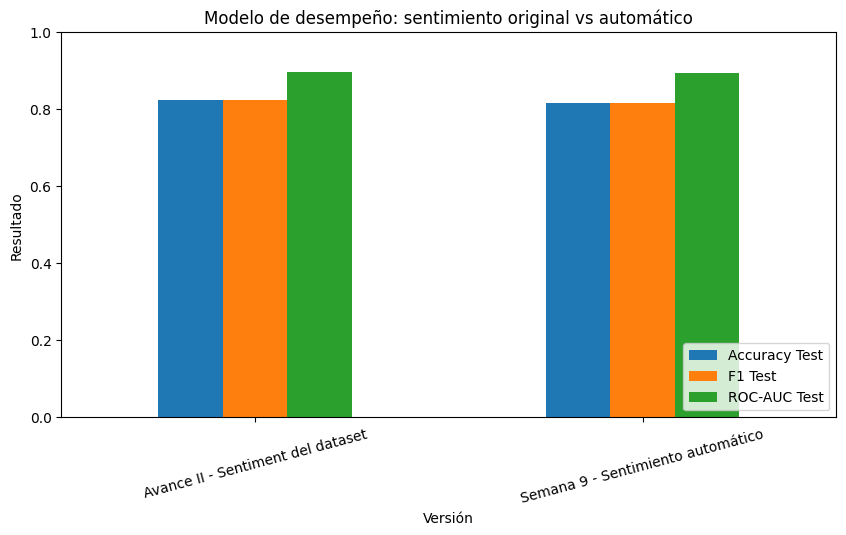

In [ ]:
comparacion_grafica = (
    comparacion_performance
    .set_index("Versión")[
        [
            "Accuracy Test",
            "F1 Test",
            "ROC-AUC Test"
        ]
    ]
)

comparacion_grafica.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Resultado")

plt.title(
    "Modelo de desempeño: "
    "sentimiento original vs automático"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=15
)

plt.legend(
    loc="lower right"
)

plt.show()

## 19. Estudio de ablación del componente de sentimiento

La integración del clasificador Linear SVC permitió sustituir las etiquetas de sentimiento suministradas por el dataset por predicciones automáticas.

Aunque el desempeño disminuyó ligeramente frente al uso de las etiquetas originales, esta arquitectura es más cercana a un escenario real.

Para determinar si las variables de sentimiento automático aportan información útil al modelo de desempeño, se realizará un estudio de ablación.

Se entrenará una nueva versión del modelo eliminando:

- `Positive_Ratio_Pred`
- `Negative_Ratio_Pred`

El resto de la configuración permanecerá sin cambios.

La comparación permitirá determinar si el componente de Sentiment Analysis contribuye realmente a la clasificación del desempeño de los videos.

In [ ]:
variables_numericas_sin_sentimiento = [
    "Log_Comment_Likes_Mean",
    "Avg_Comment_Words"
]

X_sin_sentimiento = datos_nlp_auto[
    [
        "Comments_Text"
    ] +
    variables_numericas_sin_sentimiento
].copy()

X_train_sin_sentimiento = (
    X_sin_sentimiento.loc[
        X_train.index
    ]
)

X_test_sin_sentimiento = (
    X_sin_sentimiento.loc[
        X_test.index
    ]
)

print(
    "Entrenamiento:",
    X_train_sin_sentimiento.shape
)

print(
    "Prueba:",
    X_test_sin_sentimiento.shape
)

print(
    "\nVariables utilizadas:"
)

print(
    X_sin_sentimiento.columns.tolist()
)

Entrenamiento: (1493, 3)
Prueba: (374, 3)

Variables utilizadas:
['Comments_Text', 'Log_Comment_Likes_Mean', 'Avg_Comment_Words']


In [ ]:
procesador_numerico_sin_sentimiento = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

preprocesador_sin_sentimiento = ColumnTransformer(
    transformers=[

        (
            "text",
            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                stop_words=stopwords_nlp,
                sublinear_tf=True
            ),
            "Comments_Text"
        ),

        (
            "num",
            procesador_numerico_sin_sentimiento,
            variables_numericas_sin_sentimiento
        )
    ]
)

modelo_sin_sentimiento = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_sin_sentimiento
        ),
        (
            "modelo",
            LogisticRegression(
                C=5,
                class_weight=None,
                max_iter=5000,
                random_state=42
            )
        )
    ]
)

print(
    "Pipeline sin variables de sentimiento creado correctamente."
)

Pipeline sin variables de sentimiento creado correctamente.


In [ ]:
scores_sin_sentimiento = cross_validate(

    modelo_sin_sentimiento,

    X_train_sin_sentimiento,
    y_train_auto,

    cv=cv,

    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1": "f1",
        "ROC_AUC": "roc_auc"
    },

    n_jobs=-1
)

metricas_cv_sin_sentimiento = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],

    "Sin sentimiento": [

        scores_sin_sentimiento[
            "test_Accuracy"
        ].mean(),

        scores_sin_sentimiento[
            "test_Precision"
        ].mean(),

        scores_sin_sentimiento[
            "test_Recall"
        ].mean(),

        scores_sin_sentimiento[
            "test_F1"
        ].mean(),

        scores_sin_sentimiento[
            "test_ROC_AUC"
        ].mean()
    ],

    "Con sentimiento automático": [

        scores_performance_auto[
            "test_Accuracy"
        ].mean(),

        scores_performance_auto[
            "test_Precision"
        ].mean(),

        scores_performance_auto[
            "test_Recall"
        ].mean(),

        scores_performance_auto[
            "test_F1"
        ].mean(),

        scores_performance_auto[
            "test_ROC_AUC"
        ].mean()
    ]
})

display(
    metricas_cv_sin_sentimiento.round(4)
)

,Métrica,Sin sentimiento,Con sentimiento automático
0,Accuracy,0.8111,0.8178
1,Precision,0.8090,0.8164
2,Recall,0.8153,0.8207
3,F1,0.8120,0.8184
4,ROC-AUC,0.8929,0.8931


In [ ]:
f1_cv_sin_sentimiento = (
    scores_sin_sentimiento[
        "test_F1"
    ].mean()
)

f1_cv_con_sentimiento = (
    scores_performance_auto[
        "test_F1"
    ].mean()
)

diferencia_sentimiento = (
    f1_cv_con_sentimiento
    - f1_cv_sin_sentimiento
)

print(
    "F1 CV sin sentimiento:",
    round(
        f1_cv_sin_sentimiento,
        4
    )
)

print(
    "F1 CV con sentimiento automático:",
    round(
        f1_cv_con_sentimiento,
        4
    )
)

print(
    "\nDiferencia aportada por las variables de sentimiento:",
    round(
        diferencia_sentimiento,
        4
    )
)

if diferencia_sentimiento > 0:

    print(
        "\nConclusión: las variables de sentimiento "
        "mejoran el modelo."
    )

elif diferencia_sentimiento < 0:

    print(
        "\nConclusión: las variables de sentimiento "
        "no mejoran el F1 del modelo."
    )

else:

    print(
        "\nConclusión: no existe diferencia en F1."
    )

F1 CV sin sentimiento: 0.812
F1 CV con sentimiento automático: 0.8184

Diferencia aportada por las variables de sentimiento: 0.0064

Conclusión: las variables de sentimiento mejoran el modelo.


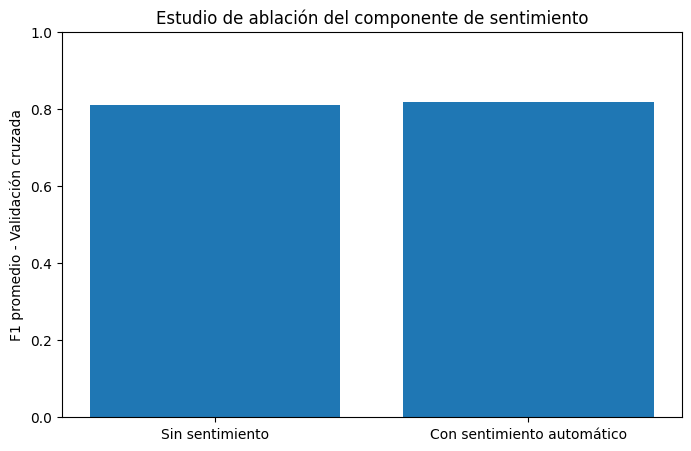

In [ ]:
comparacion_ablacion = pd.DataFrame({

    "Configuración": [
        "Sin sentimiento",
        "Con sentimiento automático"
    ],

    "F1 CV": [
        f1_cv_sin_sentimiento,
        f1_cv_con_sentimiento
    ]
})

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    comparacion_ablacion[
        "Configuración"
    ],
    comparacion_ablacion[
        "F1 CV"
    ]
)

plt.ylabel(
    "F1 promedio - Validación cruzada"
)

plt.title(
    "Estudio de ablación del componente de sentimiento"
)

plt.ylim(
    0,
    1
)

plt.show()

## 20. Cierre técnico del Avance III

En esta sección se consolidan los resultados obtenidos durante las iteraciones de la Semana 9 y se almacenan los artefactos necesarios para continuar con el despliegue del sistema en la siguiente etapa del proyecto.

In [ ]:
resumen_avance3 = pd.DataFrame({

    "Etapa": [
        "Sentimiento inicial",
        "Sentimiento optimizado",
        "Desempeño Avance II",
        "Desempeño con sentimiento automático",
        "Ablación sin sentimiento"
    ],

    "Modelo": [
        "Linear SVC",
        "Linear SVC optimizado",
        "Logistic Regression",
        "Linear SVC + Logistic Regression",
        "Logistic Regression"
    ],

    "Métrica principal": [
        "Macro F1",
        "Macro F1",
        "F1",
        "F1",
        "F1"
    ],

    "Validación cruzada": [
        0.6182,
        0.6478,
        0.8267,
        f1_cv_con_sentimiento,
        f1_cv_sin_sentimiento
    ],

    "Prueba": [
        None,
        f1_macro_sent,
        0.8235,
        f1_perf_auto,
        None
    ]
})

print(
    "RESUMEN DE ITERACIONES - AVANCE III"
)

display(
    resumen_avance3.round(4)
)

RESUMEN DE ITERACIONES - AVANCE III


,Etapa,Modelo,Métrica principal,Validación cruzada,Prueba
0,Sentimiento inicial,Linear SVC,Macro F1,0.6182,NaN
1,Sentimiento optimizado,Linear SVC optimizado,Macro F1,0.6478,0.6471
2,Desempeño Avance II,Logistic Regression,F1,0.8267,0.8235
3,Desempeño con sentimiento automático,Linear SVC + Logistic Regression,F1,0.8184,0.8150
4,Ablación sin sentimiento,Logistic Regression,F1,0.8120,NaN


In [ ]:
ruta_resultados_avance3 = (
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "resultados_avance3_youtube.csv"
)

resumen_avance3.to_csv(
    ruta_resultados_avance3,
    index=False
)

print(
    "Resultados guardados correctamente:"
)

print(
    ruta_resultados_avance3
)

Resultados guardados correctamente:
/content/drive/MyDrive/Colab Notebooks/resultados_avance3_youtube.csv


In [ ]:
import joblib

artefacto_avance3 = {

    "version":
        "Avance III - Semana 9",

    "tipo":
        "modelo_evaluacion",

    "modelo_sentimiento":
        modelo_sentimiento_para_stack,

    "modelo_desempeno":
        modelo_performance_auto,

    "umbral_views":
        umbral_views,

    "clases_sentimiento": {
        0: "Negativo",
        1: "Neutral",
        2: "Positivo"
    },

    "variables_modelo_desempeno": [
        "Comments_Text",
        "Log_Comment_Likes_Mean",
        "Positive_Ratio_Pred",
        "Negative_Ratio_Pred",
        "Avg_Comment_Words"
    ],

    "metricas_sentimiento": {

        "macro_f1_cv":
            float(f1_svc_optimizado),

        "macro_f1_test":
            float(f1_macro_sent),

        "balanced_accuracy_test":
            float(balanced_accuracy_sent)
    },

    "metricas_desempeno": {

        "accuracy_test":
            float(accuracy_perf_auto),

        "precision_test":
            float(precision_perf_auto),

        "recall_test":
            float(recall_perf_auto),

        "f1_test":
            float(f1_perf_auto),

        "roc_auc_test":
            float(auc_perf_auto)
    },

    "preprocesamiento_texto": {

        "minusculas":
            True,

        "eliminar_urls":
            True,

        "eliminar_caracteres_especiales":
            True,

        "eliminar_espacios_repetidos":
            True
    }
}

print(
    "Artefacto del Avance III preparado correctamente."
)

Artefacto del Avance III preparado correctamente.


In [ ]:
ruta_modelo_avance3 = (
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "modelo_nlp_youtube_avance3.pkl"
)

joblib.dump(
    artefacto_avance3,
    ruta_modelo_avance3
)

print(
    "MODELO DEL AVANCE III GUARDADO CORRECTAMENTE"
)

print(
    ruta_modelo_avance3
)

MODELO DEL AVANCE III GUARDADO CORRECTAMENTE
/content/drive/MyDrive/Colab Notebooks/modelo_nlp_youtube_avance3.pkl


In [ ]:
artefacto_verificacion = joblib.load(
    ruta_modelo_avance3
)

print(
    "Artefacto cargado correctamente."
)

print(
    "\nVersión:",
    artefacto_verificacion[
        "version"
    ]
)

print(
    "\nComponentes disponibles:"
)

for clave in (
    artefacto_verificacion
    .keys()
):
    print(
        "-",
        clave
    )

Artefacto cargado correctamente.

Versión: Avance III - Semana 9

Componentes disponibles:
- version
- tipo
- modelo_sentimiento
- modelo_desempeno
- umbral_views
- clases_sentimiento
- variables_modelo_desempeno
- metricas_sentimiento
- metricas_desempeno
- preprocesamiento_texto


In [ ]:
comentario_verificacion = (
    sentimiento_test_performance[
        "Comment_Clean"
    ].iloc[0]
)

prediccion_verificacion = (
    artefacto_verificacion[
        "modelo_sentimiento"
    ]
    .predict(
        [comentario_verificacion]
    )[0]
)

nombre_sentimiento = (
    artefacto_verificacion[
        "clases_sentimiento"
    ][
        int(
            prediccion_verificacion
        )
    ]
)

print(
    "Comentario:"
)

print(
    comentario_verificacion
)

print(
    "\nSentimiento predicho:"
)

print(
    nombre_sentimiento
)

Comentario:
wow you really went to town on the psu test rack that s a serious bit of kit very flexible good choices wouldn t surprise me if choma start offering this bespoke rack to the psu makers they all watch your videos so they ll want to make sure it passes on this exact same rack you can really push the industry here well done open source the test interface hardware and software

Sentimiento predicho:
Positivo


In [ ]:
ejemplo_video = (
    X_test_auto
    .iloc[[0]]
)

prediccion_desempeno = (
    artefacto_verificacion[
        "modelo_desempeno"
    ]
    .predict(
        ejemplo_video
    )[0]
)

probabilidad_desempeno = (
    artefacto_verificacion[
        "modelo_desempeno"
    ]
    .predict_proba(
        ejemplo_video
    )[0, 1]
)

print(
    "PREDICCIÓN DE VERIFICACIÓN"
)

print(
    "Clase:",
    int(
        prediccion_desempeno
    )
)

print(
    "Interpretación:",
    (
        "Desempeño alto"
        if prediccion_desempeno == 1
        else "Desempeño bajo"
    )
)

print(
    "Probabilidad de desempeño alto:",
    round(
        probabilidad_desempeno,
        4
    )
)

PREDICCIÓN DE VERIFICACIÓN
Clase: 0
Interpretación: Desempeño bajo
Probabilidad de desempeño alto: 0.0082


In [ ]:
metricas_finales_avance3 = pd.DataFrame({

    "Indicador": [

        "Sentiment - Macro F1 inicial CV",

        "Sentiment - Macro F1 optimizado CV",

        "Sentiment - Macro F1 test",

        "Sentiment - Balanced Accuracy test",

        "Performance Avance II - F1 test",

        "Performance Avance II - ROC-AUC test",

        "Performance automático - Accuracy test",

        "Performance automático - Precision test",

        "Performance automático - Recall test",

        "Performance automático - F1 test",

        "Performance automático - ROC-AUC test",

        "Ablación sin sentimiento - F1 CV",

        "Con sentimiento automático - F1 CV"
    ],

    "Valor": [

        0.6182,

        f1_svc_optimizado,

        f1_macro_sent,

        balanced_accuracy_sent,

        0.8235,

        0.8969,

        accuracy_perf_auto,

        precision_perf_auto,

        recall_perf_auto,

        f1_perf_auto,

        auc_perf_auto,

        f1_cv_sin_sentimiento,

        f1_cv_con_sentimiento
    ]
})

ruta_metricas_avance3 = (
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "metricas_finales_avance3.csv"
)

metricas_finales_avance3.to_csv(
    ruta_metricas_avance3,
    index=False
)

display(
    metricas_finales_avance3.round(4)
)

print(
    "\nArchivo guardado:"
)

print(
    ruta_metricas_avance3
)

,Indicador,Valor
0,Sentiment - Macro F1 inicial CV,0.6182
1,Sentiment - Macro F1 optimizado CV,0.6478
2,Sentiment - Macro F1 test,0.6471
3,Sentiment - Balanced Accuracy test,0.6563
4,Performance Avance II - F1 test,0.8235
5,Performance Avance II - ROC-AUC test,0.8969
6,Performance automático - Accuracy test,0.8155
7,Performance automático - Precision test,0.8172
8,Performance automático - Recall test,0.8128
9,Performance automático - F1 test,0.8150



Archivo guardado:
/content/drive/MyDrive/Colab Notebooks/metricas_finales_avance3.csv


## Fin del Avance III

Se completaron las iteraciones correspondientes a la Semana 9.

Los resultados, métricas y modelos obtenidos fueron almacenados para su documentación y para continuar con la etapa de despliegue del proyecto.

# Avance IV - Semana 10
## Desarrollo de la interfaz del modelo NLP

En esta etapa se desarrolla una interfaz web para permitir que un usuario utilice el modelo sin necesidad de interactuar directamente con el código.

La aplicación recibirá comentarios de un video de YouTube y sus respectivos likes. A partir de estos datos realizará automáticamente:

1. Limpieza y preprocesamiento NLP.
2. Clasificación de sentimiento mediante Linear SVC.
3. Cálculo de proporciones de comentarios positivos, neutrales y negativos.
4. Construcción de las variables requeridas por el modelo.
5. Clasificación del desempeño mediante Logistic Regression.
6. Presentación de los resultados al usuario.

La interfaz será desarrollada con Streamlit y posteriormente será desplegada en la nube.

In [ ]:
!pip -q install streamlit

import os
import shutil

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)

ruta_app = "/content/youtube_app"

os.makedirs(
    ruta_app,
    exist_ok=True
)

ruta_modelo_drive = (
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "modelo_nlp_youtube_avance3.pkl"
)

ruta_modelo_app = (
    "/content/youtube_app/"
    "modelo_nlp_youtube_avance3.pkl"
)

shutil.copy2(
    ruta_modelo_drive,
    ruta_modelo_app
)

print(
    "Carpeta de aplicación creada:"
)

print(
    ruta_app
)

print(
    "\nModelo copiado correctamente:"
)

print(
    ruta_modelo_app
)

print(
    "\n¿Existe el modelo?"
)

print(
    os.path.exists(
        ruta_modelo_app
    )
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de aplicación creada:
/content/youtube_app

Modelo copiado correctamente:
/content/youtube_app/modelo_nlp_youtube_avance3.pkl

¿Existe el modelo?
True


In [ ]:
%%writefile /content/youtube_app/app.py

import re
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st


# =========================================================
# CONFIGURACIÓN GENERAL
# =========================================================

st.set_page_config(
    page_title="YouTube Performance NLP",
    page_icon="▶️",
    layout="wide"
)

RUTA_MODELO = (
    Path(__file__).resolve().parent
    / "modelo_nlp_youtube_avance3.pkl"
)


# =========================================================
# CARGA DEL MODELO
# =========================================================

@st.cache_resource
def cargar_artefacto():

    return joblib.load(
        RUTA_MODELO
    )


artefacto = cargar_artefacto()

modelo_sentimiento = (
    artefacto[
        "modelo_sentimiento"
    ]
)

modelo_desempeno = (
    artefacto[
        "modelo_desempeno"
    ]
)

clases_sentimiento = (
    artefacto[
        "clases_sentimiento"
    ]
)

umbral_views = (
    artefacto.get(
        "umbral_views",
        None
    )
)


# =========================================================
# PREPROCESAMIENTO
# =========================================================

def limpiar_comentario(texto):

    texto = str(texto).lower()

    # Eliminar enlaces
    texto = re.sub(
        r"http\S+|www\S+",
        " ",
        texto
    )

    # Eliminar caracteres especiales
    texto = re.sub(
        r"[^a-záéíóúüñ\s]",
        " ",
        texto
    )

    # Eliminar espacios repetidos
    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto


def preparar_comentarios(df):

    datos = df.copy()

    if "Comment" not in datos.columns:

        raise ValueError(
            "Los datos deben contener "
            "una columna llamada Comment."
        )

    if "Likes" not in datos.columns:

        datos[
            "Likes"
        ] = 0

    datos[
        "Comment"
    ] = (
        datos[
            "Comment"
        ]
        .fillna("")
        .astype(str)
    )

    datos[
        "Likes"
    ] = (
        pd.to_numeric(
            datos[
                "Likes"
            ],
            errors="coerce"
        )
        .fillna(0)
        .clip(lower=0)
    )

    datos[
        "Comment_Clean"
    ] = (
        datos[
            "Comment"
        ]
        .apply(
            limpiar_comentario
        )
    )

    # Eliminar comentarios vacíos
    datos = datos[
        datos[
            "Comment_Clean"
        ].str.len() > 0
    ].copy()

    return datos


# =========================================================
# FUNCIÓN PRINCIPAL DE PREDICCIÓN
# =========================================================

def analizar_video(df):

    comentarios = (
        preparar_comentarios(
            df
        )
    )

    if len(comentarios) == 0:

        raise ValueError(
            "Debe ingresar al menos "
            "un comentario válido."
        )

    # -----------------------------------------
    # 1. SENTIMIENTO
    # -----------------------------------------

    pred_sentimiento = (
        modelo_sentimiento.predict(
            comentarios[
                "Comment_Clean"
            ].tolist()
        )
    )

    comentarios[
        "Sentiment_Pred"
    ] = pred_sentimiento

    comentarios[
        "Sentimiento"
    ] = [
        clases_sentimiento[
            int(valor)
        ]
        for valor
        in pred_sentimiento
    ]

    positive_ratio = (
        pred_sentimiento == 2
    ).mean()

    neutral_ratio = (
        pred_sentimiento == 1
    ).mean()

    negative_ratio = (
        pred_sentimiento == 0
    ).mean()

    # -----------------------------------------
    # 2. VARIABLES POR VIDEO
    # -----------------------------------------

    comments_text = " ".join(
        comentarios[
            "Comment_Clean"
        ].tolist()
    )

    avg_comment_words = (
        comentarios[
            "Comment_Clean"
        ]
        .str.split()
        .str.len()
        .mean()
    )

    comment_likes_mean = (
        comentarios[
            "Likes"
        ].mean()
    )

    log_comment_likes_mean = (
        np.log1p(
            comment_likes_mean
        )
    )

    # -----------------------------------------
    # 3. DATAFRAME PARA MODELO PRINCIPAL
    # -----------------------------------------

    entrada_modelo = pd.DataFrame({
        "Comments_Text": [
            comments_text
        ],

        "Log_Comment_Likes_Mean": [
            log_comment_likes_mean
        ],

        "Positive_Ratio_Pred": [
            positive_ratio
        ],

        "Negative_Ratio_Pred": [
            negative_ratio
        ],

        "Avg_Comment_Words": [
            avg_comment_words
        ]
    })

    # -----------------------------------------
    # 4. PREDICCIÓN DE DESEMPEÑO
    # -----------------------------------------

    prediccion = int(
        modelo_desempeno.predict(
            entrada_modelo
        )[0]
    )

    probabilidad_alto = float(
        modelo_desempeno.predict_proba(
            entrada_modelo
        )[0, 1]
    )

    resultado = {

        "prediccion":
            prediccion,

        "probabilidad_alto":
            probabilidad_alto,

        "positive_ratio":
            float(positive_ratio),

        "neutral_ratio":
            float(neutral_ratio),

        "negative_ratio":
            float(negative_ratio),

        "avg_comment_words":
            float(avg_comment_words),

        "comment_likes_mean":
            float(comment_likes_mean),

        "log_comment_likes_mean":
            float(log_comment_likes_mean),

        "comentarios":
            comentarios,

        "entrada_modelo":
            entrada_modelo
    }

    return resultado


# =========================================================
# INTERFAZ
# =========================================================

st.title(
    "▶️ YouTube Performance NLP"
)

st.write(
    """
    Aplicación para analizar comentarios de un video de
    YouTube y estimar su nivel de desempeño utilizando
    Procesamiento de Lenguaje Natural.
    """
)

st.info(
    """
    El sistema analiza automáticamente el sentimiento de
    los comentarios y posteriormente utiliza esa información,
    junto con características textuales y estadísticas,
    para clasificar el desempeño del video.
    """
)


# =========================================================
# ENTRADA DE DATOS
# =========================================================

st.header(
    "1. Ingreso de comentarios"
)

modo_entrada = st.radio(
    "Seleccione el método de entrada:",
    [
        "Ingresar manualmente",
        "Cargar archivo CSV"
    ],
    horizontal=True
)


# ---------------------------------------------------------
# ENTRADA MANUAL
# ---------------------------------------------------------

if (
    modo_entrada
    == "Ingresar manualmente"
):

    st.write(
        """
        Escriba los comentarios del video.
        La columna Likes corresponde a los likes
        recibidos por cada comentario.
        """
    )

    tabla_inicial = pd.DataFrame({
        "Comment": [
            "",
            "",
            "",
            "",
            ""
        ],

        "Likes": [
            0,
            0,
            0,
            0,
            0
        ]
    })

    datos_usuario = st.data_editor(
        tabla_inicial,
        num_rows="dynamic",
        hide_index=True,
        use_container_width=True,

        column_config={

            "Comment":
                st.column_config.TextColumn(
                    "Comentario",
                    width="large"
                ),

            "Likes":
                st.column_config.NumberColumn(
                    "Likes",
                    min_value=0,
                    step=1
                )
        }
    )


# ---------------------------------------------------------
# CARGA CSV
# ---------------------------------------------------------

else:

    archivo = st.file_uploader(
        "Seleccione un archivo CSV",
        type=[
            "csv"
        ]
    )

    if archivo is not None:

        datos_usuario = pd.read_csv(
            archivo
        )

        if (
            "Comment"
            not in datos_usuario.columns
        ):

            st.error(
                "El CSV debe contener una "
                "columna llamada Comment."
            )

            st.stop()

        if (
            "Likes"
            not in datos_usuario.columns
        ):

            datos_usuario[
                "Likes"
            ] = 0

            st.warning(
                """
                El archivo no contiene la columna Likes.
                Se utilizará 0 para esos valores.
                """
            )

        st.write(
            "Vista previa:"
        )

        st.dataframe(
            datos_usuario[
                [
                    "Comment",
                    "Likes"
                ]
            ].head(20),
            use_container_width=True
        )

    else:

        datos_usuario = (
            pd.DataFrame(
                columns=[
                    "Comment",
                    "Likes"
                ]
            )
        )


# =========================================================
# ANÁLISIS
# =========================================================

st.header(
    "2. Ejecutar análisis"
)

if st.button(
    "🔍 Analizar video",
    type="primary",
    use_container_width=True
):

    try:

        resultado = analizar_video(
            datos_usuario
        )

        st.divider()

        st.header(
            "3. Resultados"
        )

        # -------------------------------------
        # RESUMEN SENTIMIENTO
        # -------------------------------------

        st.subheader(
            "Análisis de sentimiento"
        )

        col1, col2, col3, col4 = (
            st.columns(4)
        )

        col1.metric(
            "Comentarios analizados",
            len(
                resultado[
                    "comentarios"
                ]
            )
        )

        col2.metric(
            "Positivos",
            f"""
            {
                resultado[
                    "positive_ratio"
                ] * 100:.1f
            } %
            """
        )

        col3.metric(
            "Neutrales",
            f"""
            {
                resultado[
                    "neutral_ratio"
                ] * 100:.1f
            } %
            """
        )

        col4.metric(
            "Negativos",
            f"""
            {
                resultado[
                    "negative_ratio"
                ] * 100:.1f
            } %
            """
        )


        # -------------------------------------
        # GRÁFICA DE SENTIMIENTO
        # -------------------------------------

        distribucion = pd.DataFrame({

            "Proporción": [

                resultado[
                    "negative_ratio"
                ],

                resultado[
                    "neutral_ratio"
                ],

                resultado[
                    "positive_ratio"
                ]
            ]

        }, index=[

            "Negativo",
            "Neutral",
            "Positivo"

        ])

        st.bar_chart(
            distribucion
        )


        # -------------------------------------
        # RESULTADO PRINCIPAL
        # -------------------------------------

        st.subheader(
            "Predicción de desempeño"
        )

        if (
            resultado[
                "prediccion"
            ] == 1
        ):

            st.success(
                "📈 DESEMPEÑO ESTIMADO: ALTO"
            )

        else:

            st.warning(
                "📉 DESEMPEÑO ESTIMADO: BAJO"
            )


        probabilidad = (
            resultado[
                "probabilidad_alto"
            ]
        )

        st.metric(
            "Probabilidad de desempeño alto",
            f"{probabilidad * 100:.2f} %"
        )

        st.progress(
            int(
                probabilidad * 100
            )
        )


        # -------------------------------------
        # UMBRAL DEL MODELO
        # -------------------------------------

        if (
            umbral_views
            is not None
        ):

            umbral_texto = (
                f"{int(umbral_views):,}"
                .replace(
                    ",",
                    "."
                )
            )

            st.caption(
                "En el conjunto de datos utilizado "
                "para entrenar el modelo, desempeño "
                "alto corresponde a aproximadamente "
                f"{umbral_texto} visualizaciones o más."
            )


        # -------------------------------------
        # DETALLE POR COMENTARIO
        # -------------------------------------

        st.subheader(
            "Detalle de comentarios"
        )

        tabla_resultados = (
            resultado[
                "comentarios"
            ][
                [
                    "Comment",
                    "Likes",
                    "Sentimiento"
                ]
            ]
            .rename(
                columns={
                    "Comment":
                        "Comentario",

                    "Likes":
                        "Likes"
                }
            )
        )

        st.dataframe(
            tabla_resultados,
            use_container_width=True,
            hide_index=True
        )


        # -------------------------------------
        # INFORMACIÓN TÉCNICA
        # -------------------------------------

        with st.expander(
            "Ver variables calculadas por el modelo"
        ):

            st.write(
                "Promedio de likes por comentario:",
                round(
                    resultado[
                        "comment_likes_mean"
                    ],
                    4
                )
            )

            st.write(
                "Log promedio de likes:",
                round(
                    resultado[
                        "log_comment_likes_mean"
                    ],
                    4
                )
            )

            st.write(
                "Promedio de palabras por comentario:",
                round(
                    resultado[
                        "avg_comment_words"
                    ],
                    4
                )
            )

            st.dataframe(
                resultado[
                    "entrada_modelo"
                ],
                use_container_width=True
            )


        st.divider()

        st.caption(
            """
            Nota: el modelo utiliza comentarios posteriores
            a la publicación del video. Por lo tanto,
            el resultado debe interpretarse como una
            estimación del desempeño observado a partir
            de la reacción de la audiencia y no como un
            pronóstico previo a la publicación.
            """
        )

    except Exception as error:

        st.error(
            f"No fue posible realizar el análisis: {error}"
        )

Writing /content/youtube_app/app.py


In [ ]:
import py_compile

ruta_app_py = (
    "/content/youtube_app/app.py"
)

try:

    py_compile.compile(
        ruta_app_py,
        doraise=True
    )

    print(
        "✅ app.py compilado correctamente."
    )

    print(
        "No se encontraron errores de sintaxis."
    )

except Exception as error:

    print(
        "❌ Error en app.py:"
    )

    print(
        error
    )

✅ app.py compilado correctamente.
No se encontraron errores de sintaxis.


In [ ]:
import subprocess
import time
import requests

log_streamlit = open(
    "/content/streamlit_test.log",
    "w"
)

proceso_streamlit = subprocess.Popen(

    [
        "streamlit",
        "run",
        "/content/youtube_app/app.py",

        "--server.headless=true",

        "--server.port=8501"
    ],

    stdout=log_streamlit,
    stderr=subprocess.STDOUT
)

time.sleep(
    8
)

try:

    respuesta = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )

    print(
        "Código HTTP:",
        respuesta.status_code
    )

    print(
        "Estado de Streamlit:",
        respuesta.text
    )

finally:

    proceso_streamlit.terminate()

    log_streamlit.close()

Código HTTP: 200
Estado de Streamlit: ok


In [ ]:
import sys
import streamlit
import pandas
import numpy
import sklearn
import joblib

print("VERSIÓN DE PYTHON")
print(sys.version)

print("\nVERSIONES DEL PROYECTO")
print("streamlit:", streamlit.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

VERSIÓN DE PYTHON
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

VERSIONES DEL PROYECTO
streamlit: 1.66.1
pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
joblib: 1.6.0


In [ ]:
from pathlib import Path

requirements = f"""streamlit=={streamlit.__version__}
pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

ruta_requirements = Path(
    "/content/youtube_app/requirements.txt"
)

ruta_requirements.write_text(
    requirements
)

print("requirements.txt creado:\n")
print(requirements)

In [ ]:
%%writefile /content/youtube_app/README.md

# YouTube Performance NLP

Proyecto desarrollado para la asignatura Procesamiento de Lenguaje Natural de la Especialización en Inteligencia Artificial de la Universidad de Cundinamarca.

## Objetivo

Desarrollar un sistema de Procesamiento de Lenguaje Natural capaz de analizar comentarios de videos de YouTube y estimar su nivel de desempeño.

## Arquitectura

Comentarios de YouTube
→ Limpieza NLP
→ Linear SVC
→ Análisis de sentimiento
→ Agregación por video
→ TF-IDF + variables estadísticas
→ Logistic Regression
→ Desempeño alto / bajo

## Modelos

### Análisis de sentimiento

Se utilizó Linear SVC optimizado mediante GridSearchCV.

Resultados principales:

- Macro F1 validación cruzada: 0.6478
- Macro F1 prueba: 0.6471
- Balanced Accuracy prueba: 0.6563

### Clasificación de desempeño

Se utilizó Logistic Regression.

Resultados con sentimiento automático:

- Accuracy: 0.8155
- F1-score: 0.8150
- ROC-AUC: 0.8952

## Variables utilizadas

- Comments_Text
- Log_Comment_Likes_Mean
- Positive_Ratio_Pred
- Negative_Ratio_Pred
- Avg_Comment_Words

## Interfaz

La aplicación fue desarrollada con Streamlit.

El usuario puede:

- ingresar comentarios manualmente;
- indicar los likes de cada comentario;
- cargar comentarios desde un archivo CSV;
- obtener el sentimiento de cada comentario;
- visualizar la distribución de sentimientos;
- obtener una estimación de desempeño alto o bajo;
- visualizar la probabilidad estimada.

## Dataset

YouTube Statistics - Kaggle.

Archivos utilizados:

- videos-stats.csv
- comments.csv

## Tecnologías

- Python
- Google Colab
- pandas
- NumPy
- scikit-learn
- TF-IDF
- Streamlit
- joblib

## Nota metodológica

Los comentarios son señales posteriores a la publicación del video. Por esta razón, el resultado se interpreta como una estimación del desempeño observado a partir de la reacción de la audiencia y no como un pronóstico previo a la publicación.

Writing /content/youtube_app/README.md


In [ ]:
import subprocess
import time
import re
import os
import requests

# ---------------------------------------------------------
# Descargar cloudflared
# ---------------------------------------------------------

if not os.path.exists(
    "/content/cloudflared"
):

    !wget -q \
    https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
    -O /content/cloudflared

    !chmod +x /content/cloudflared


# ---------------------------------------------------------
# Detener procesos anteriores
# ---------------------------------------------------------

!pkill -f "streamlit run" 2>/dev/null || true
!pkill -f "cloudflared tunnel" 2>/dev/null || true

time.sleep(2)


# ---------------------------------------------------------
# Iniciar Streamlit
# ---------------------------------------------------------

streamlit_log = open(
    "/content/streamlit_publico.log",
    "w"
)

proceso_streamlit = subprocess.Popen(

    [
        "streamlit",
        "run",
        "/content/youtube_app/app.py",
        "--server.headless=true",
        "--server.port=8501",
        "--server.address=0.0.0.0"
    ],

    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)

time.sleep(8)


# ---------------------------------------------------------
# Verificar Streamlit
# ---------------------------------------------------------

respuesta = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=10
)

print(
    "Estado Streamlit:",
    respuesta.status_code,
    respuesta.text
)


# ---------------------------------------------------------
# Iniciar Cloudflare Tunnel
# ---------------------------------------------------------

cloudflare_log = open(
    "/content/cloudflare.log",
    "w"
)

proceso_cloudflare = subprocess.Popen(

    [
        "/content/cloudflared",
        "tunnel",
        "--url",
        "http://localhost:8501"
    ],

    stdout=cloudflare_log,
    stderr=subprocess.STDOUT
)


# ---------------------------------------------------------
# Esperar y buscar URL
# ---------------------------------------------------------

url_publica = None

for intento in range(30):

    time.sleep(2)

    with open(
        "/content/cloudflare.log",
        "r"
    ) as archivo:

        contenido = archivo.read()

    coincidencia = re.search(
        r"https://[-a-zA-Z0-9]+\.trycloudflare\.com",
        contenido
    )

    if coincidencia:

        url_publica = (
            coincidencia.group(0)
        )

        break


print("\n" + "=" * 60)

if url_publica:

    print(
        "✅ APLICACIÓN PUBLICADA TEMPORALMENTE"
    )

    print(
        "\nAbre este enlace:"
    )

    print(
        url_publica
    )

else:

    print(
        "❌ No fue posible encontrar la URL."
    )

    print(
        "\nContenido del log:"
    )

    print(
        contenido
    )

print("=" * 60)

^C
^C
Estado Streamlit: 200 ok

✅ APLICACIÓN PUBLICADA TEMPORALMENTE

Abre este enlace:
https://manuals-together-anonymous-wrist.trycloudflare.com


In [ ]:
from pathlib import Path

ruta_app_py = Path(
    "/content/youtube_app/app.py"
)

codigo = ruta_app_py.read_text()

codigo = codigo.replace(
'''        col2.metric(
            "Positivos",
            f"""
            {
                resultado[
                    "positive_ratio"
                ] * 100:.1f
            } %
            """
        )''',
'''        col2.metric(
            "Positivos",
            f"{resultado['positive_ratio'] * 100:.1f} %"
        )'''
)

codigo = codigo.replace(
'''        col3.metric(
            "Neutrales",
            f"""
            {
                resultado[
                    "neutral_ratio"
                ] * 100:.1f
            } %
            """
        )''',
'''        col3.metric(
            "Neutrales",
            f"{resultado['neutral_ratio'] * 100:.1f} %"
        )'''
)

codigo = codigo.replace(
'''        col4.metric(
            "Negativos",
            f"""
            {
                resultado[
                    "negative_ratio"
                ] * 100:.1f
            } %
            """
        )''',
'''        col4.metric(
            "Negativos",
            f"{resultado['negative_ratio'] * 100:.1f} %"
        )'''
)

ruta_app_py.write_text(
    codigo
)

print(
    "✅ Porcentajes corregidos en app.py"
)

✅ Porcentajes corregidos en app.py


In [ ]:
import py_compile

try:

    py_compile.compile(
        "/content/youtube_app/app.py",
        doraise=True
    )

    print(
        "✅ app.py corregido y compilado correctamente."
    )

except Exception as error:

    print(
        "❌ Error:"
    )

    print(
        error
    )

✅ app.py corregido y compilado correctamente.


In [ ]:
import subprocess
import time
import re
import os
import requests

# Detener procesos anteriores
!pkill -f "streamlit run" 2>/dev/null || true
!pkill -f "cloudflared tunnel" 2>/dev/null || true

time.sleep(2)

# Iniciar Streamlit
streamlit_log = open(
    "/content/streamlit_publico.log",
    "w"
)

proceso_streamlit = subprocess.Popen(
    [
        "streamlit",
        "run",
        "/content/youtube_app/app.py",
        "--server.headless=true",
        "--server.port=8501",
        "--server.address=0.0.0.0"
    ],
    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)

time.sleep(8)

respuesta = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=10
)

print(
    "Estado Streamlit:",
    respuesta.status_code,
    respuesta.text
)

# Reiniciar túnel
cloudflare_log = open(
    "/content/cloudflare.log",
    "w"
)

proceso_cloudflare = subprocess.Popen(
    [
        "/content/cloudflared",
        "tunnel",
        "--url",
        "http://localhost:8501"
    ],
    stdout=cloudflare_log,
    stderr=subprocess.STDOUT
)

url_publica = None

for intento in range(30):

    time.sleep(2)

    with open(
        "/content/cloudflare.log",
        "r"
    ) as archivo:

        contenido = archivo.read()

    coincidencia = re.search(
        r"https://[-a-zA-Z0-9]+\.trycloudflare\.com",
        contenido
    )

    if coincidencia:

        url_publica = coincidencia.group(0)
        break

print("\n" + "=" * 60)

if url_publica:

    print(
        "✅ NUEVA URL:"
    )

    print(
        url_publica
    )

else:

    print(
        "❌ No se encontró la URL pública."
    )

print("=" * 60)

^C
^C
Estado Streamlit: 200 ok

✅ NUEVA URL:
https://blank-acid-minister-com.trycloudflare.com
